# CausalMark — Evaluation Notebook

Evaluates Criteo uplift predictions, treatment-group summaries, confidence intervals, targeting strategies, and saved model metrics.

**Important:** predicted uplift and factual prediction accuracy do not, by themselves, establish causal impact.

In [67]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = DATA_DIR / "evaluation"
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CRITEO_PATH = DATA_DIR / "marketing_instructions" / "criteo_sample_50000.csv"
criteo_df = pd.read_csv(CRITEO_PATH)

print("Rows:", len(criteo_df))
print("Columns:", criteo_df.columns.tolist())
display(criteo_df.head())


Rows: 50000
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0


## 1. Treatment-group descriptive summary

In [68]:
group_summary = (
    criteo_df.groupby("treatment")
    .agg(
        customers=("treatment", "size"),
        conversion_rate=("conversion", "mean"),
        visit_rate=("visit", "mean"),
        exposure_rate=("exposure", "mean")
    )
    .reset_index()
)

display(group_summary)

group_summary.to_csv(
    OUTPUT_DIR / "criteo_treatment_group_summary.csv",
    index=False
)


,treatment,customers,conversion_rate,visit_rate,exposure_rate
0,0,7565,0.002247,0.037673,0.000000
1,1,42435,0.002946,0.048451,0.035537


## 2. Conversion confidence intervals

In [69]:
ci_rows = []

for treatment_value, group in criteo_df.groupby("treatment"):
    n = len(group)
    p = group["conversion"].mean()
    se = np.sqrt(p * (1 - p) / n)
    ci_rows.append({
        "treatment": treatment_value,
        "customers": n,
        "conversion_rate": p,
        "ci_lower": max(0.0, p - norm.ppf(0.975) * se),
        "ci_upper": min(1.0, p + norm.ppf(0.975) * se)
    })

conversion_ci_df = pd.DataFrame(ci_rows)
display(conversion_ci_df)

conversion_ci_df.to_csv(
    OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv",
    index=False
)


,treatment,customers,conversion_rate,ci_lower,ci_upper
0,0,7565,0.002247,0.00118,0.003314
1,1,42435,0.002946,0.00243,0.003461


## 3. Load and review existing model metrics

In [70]:
metrics_path = METRICS_DIR / "criteo_final_metrics.csv"

if metrics_path.exists():
    model_metrics_df = pd.read_csv(metrics_path)
    display(model_metrics_df)
else:
    model_metrics_df = pd.DataFrame()
    print("Model metrics file not found:", metrics_path)


,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000


## 4. Uplift targeting analysis

,target_fraction,customers_selected,mean_predicted_uplift,sum_predicted_uplift
0,0.05,1750,0.020982,36.718263
1,0.10,3500,0.012172,42.602973
2,0.20,7000,0.006302,44.115271
3,0.30,10500,0.004201,44.115271
4,0.50,17500,0.002521,44.115271
5,1.00,35000,0.000365,12.771402


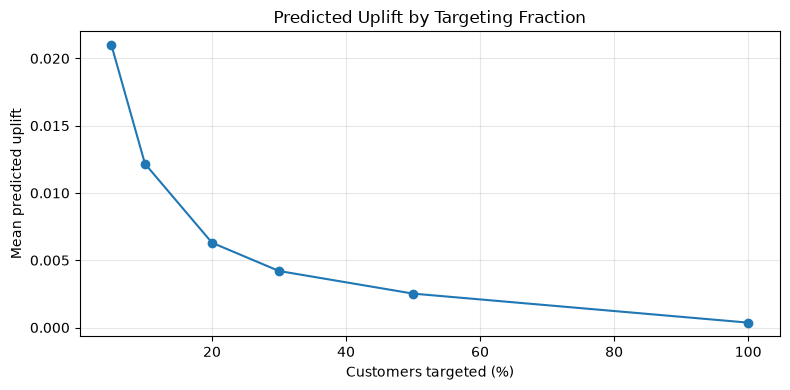

In [71]:
predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"

if predictions_path.exists():
    predictions = pd.read_csv(predictions_path)
    uplift_columns = [
        col for col in predictions.columns
        if "uplift" in col.lower()
    ]

    if uplift_columns:
        uplift_col = uplift_columns[0]
        scores = pd.to_numeric(
            predictions[uplift_col], errors="coerce"
        ).dropna().sort_values(ascending=False).reset_index(drop=True)

        targeting_rows = []
        for fraction in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
            n_selected = max(1, int(np.ceil(len(scores) * fraction)))
            selected = scores.iloc[:n_selected]
            targeting_rows.append({
                "target_fraction": fraction,
                "customers_selected": n_selected,
                "mean_predicted_uplift": selected.mean(),
                "sum_predicted_uplift": selected.sum()
            })

        targeting_df = pd.DataFrame(targeting_rows)
        display(targeting_df)
        targeting_df.to_csv(
            OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv",
            index=False
        )

        plt.figure(figsize=(8, 4))
        plt.plot(
            targeting_df["target_fraction"] * 100,
            targeting_df["mean_predicted_uplift"],
            marker="o"
        )
        plt.xlabel("Customers targeted (%)")
        plt.ylabel("Mean predicted uplift")
        plt.title("Predicted Uplift by Targeting Fraction")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print("No uplift column found:", predictions.columns.tolist())
else:
    print("Prediction file not found:", predictions_path)


## 5. Review final evaluation status

In [72]:
report_path = OUTPUT_DIR / "causalmark_final_evaluation_package.json"

if report_path.exists():
    with open(report_path, "r", encoding="utf-8") as file:
        final_package = json.load(file)

    print(json.dumps(final_package, indent=2))
else:
    print("Final evaluation package not found:", report_path)

print("\\nCausal effect verification must remain false until supported by a valid causal evaluation.")


{
  "project": "CausalMark",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "model_metrics": {
    "Factual MAE": 0.005406771777246411,
    "Factual RMSE": 0.05141600921850798,
    "Mean Predicted Uplift": 0.0003648971994799864,
    "Median Predicted Uplift": 0.0
  },
  "cross_validation": {
    "folds": 5,
    "mean_factual_rmse": 0.051543009558395914,
    "std_factual_rmse": 0.0013309563740712285,
    "mean_predicted_uplift": 0.0003410894871802435,
    "fold_results": [
      {
        "fold": 1,
        "factual_rmse": 0.052286648378504136,
        "mean_predicted_uplift": 6.55211051528567e-05
      },
      {
        "fold": 2,
        "factual_rmse": 0.04972454595883346,
        "mean_predicted_uplift": 0.00033452006875707457
      },
      {
        "fold": 3,
        "factual_rmse": 0.050847359148825495,
        "mean_predicted_uplift": 0.0005862398458242228
      },
      {
        "fold": 4,
        "factual_rmse": 0.05319465116881836,
        "mean_predicte

In [75]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
DATA_DIR = PROJECT_ROOT / "data" / "marketing_instructions"

sample_files = [
    DATA_DIR / "criteo_experiment_instructions.jsonl",
    DATA_DIR / "hillstrom_real_examples.jsonl",
    DATA_DIR / "targeted_marketing_examples.jsonl",
    DATA_DIR / "numerical_marketing_examples.jsonl",
]

for file in sample_files:
    print(f"\n{'=' * 60}")
    print(file.name)
    print("=" * 60)

    if not file.exists():
        print("Not found")
        continue

    with file.open("r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if i == 3:
                break

            try:
                record = json.loads(line)
                print(json.dumps(record, indent=2, ensure_ascii=False)[:1500])
            except json.JSONDecodeError:
                print("Invalid JSON on line", i + 1)

csv_file = DATA_DIR / "experiment_data.csv"

if csv_file.exists():
    df = pd.read_csv(csv_file, nrows=5)
    print("\nExperiment CSV columns:")
    print(df.columns.tolist())
    display(df)
else:
    print("\nExperiment CSV not found:", csv_file)



criteo_experiment_instructions.jsonl
{
  "messages": [
    {
      "role": "user",
      "content": "You are CausalMark, a marketing experiment intelligence assistant.\n\nExperiment data:\n{\n  \"dataset\": \"Criteo uplift dataset\",\n  \"control_customers\": 7565,\n  \"treatment_customers\": 42435,\n  \"control_conversion_rate\": 0.0022471910112359553,\n  \"treatment_conversion_rate\": 0.0029456816307293506,\n  \"absolute_lift\": 0.0006984906194933953,\n  \"relative_lift\": 0.3108283256745609\n}\n\nTask: Summarize the experiment results.\n\nRules:\n- Use only the supplied numbers.\n- Distinguish percentage-point difference from relative lift.\n- Do not invent revenue, profit, ROI, or statistical significance.\n- Do not claim individual customer uplift.\n- Mention that these figures come from a sampled dataset."
    },
    {
      "role": "assistant",
      "content": "The control group contained 7,565 records\nwith a conversion rate of 0.224719%. The treatment group\ncontained 42,435

,experiment_id,treatment_conversions,treatment_users,control_conversions,control_users
0,EXP001,800,10000,700,10000
1,EXP002,520,10000,500,10000
2,EXP003,450,5000,350,5000


In [76]:

import json
from pathlib import Path

PROJECT = Path.home() / "Desktop" / "CasualMark v3"
DATA_DIR = PROJECT / "data" / "marketing_instructions"

SOURCE_FILES = [
    "criteo_experiment_instructions.jsonl",
    "hillstrom_real_examples.jsonl",
    "targeted_marketing_examples.jsonl",
    "numerical_marketing_examples.jsonl",
    "causalmark_improvement_train.jsonl",
]

documents = []

for filename in SOURCE_FILES:
    path = DATA_DIR / filename

    if not path.exists():
        print("Skipping missing file:", filename)
        continue

    with path.open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                continue

            text = "\n".join(
                f"{key}: {value}"
                for key, value in record.items()
                if value is not None and str(value).strip()
            )

            if len(text.strip()) < 30:
                continue

            documents.append({
                "id": f"{filename}:{line_number}",
                "source": filename,
                "line_number": line_number,
                "text": text
            })

print("Documents collected:", len(documents))
print("Source files used:", len(set(doc["source"] for doc in documents)))

for document in documents[:3]:
    print("\nSource:", document["source"])
    print("ID:", document["id"])
    print(document["text"][:500])


Documents collected: 455
Source files used: 5

Source: criteo_experiment_instructions.jsonl
ID: criteo_experiment_instructions.jsonl:1
messages: [{'role': 'user', 'content': 'You are CausalMark, a marketing experiment intelligence assistant.\n\nExperiment data:\n{\n  "dataset": "Criteo uplift dataset",\n  "control_customers": 7565,\n  "treatment_customers": 42435,\n  "control_conversion_rate": 0.0022471910112359553,\n  "treatment_conversion_rate": 0.0029456816307293506,\n  "absolute_lift": 0.0006984906194933953,\n  "relative_lift": 0.3108283256745609\n}\n\nTask: Summarize the experiment results.\n\nRules:\n- Use only the suppli

Source: criteo_experiment_instructions.jsonl
ID: criteo_experiment_instructions.jsonl:2
messages: [{'role': 'user', 'content': 'You are CausalMark, a marketing experiment intelligence assistant.\n\nExperiment data:\n{\n  "dataset": "Criteo uplift dataset",\n  "control_customers": 7565,\n  "treatment_customers": 42435,\n  "control_conversion_rate": 0.00224719101

In [79]:

def extract_record_text(record):
    """Convert a JSONL record into searchable text."""
    if isinstance(record, str):
        return record.strip()

    if isinstance(record, dict):
        preferred_keys = [
            "text",
            "instruction",
            "input",
            "output",
            "question",
            "answer",
            "prompt",
            "response",
            "context",
            "content",
            "description"
        ]

        parts = []

        for key in preferred_keys:
            value = record.get(key)

            if value is None:
                continue

            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)

            value = str(value).strip()

            if value:
                parts.append(f"{key}: {value}")

        # Preserve records that use different field names.
        if not parts:
            parts.append(json.dumps(record, ensure_ascii=False))

        return "\n".join(parts)

    if isinstance(record, list):
        return "\n".join(
            extract_record_text(item)
            for item in record
        )

    return str(record).strip()


# Quick function test
test_record = {
    "instruction": "Evaluate a marketing campaign",
    "input": "Compare treatment and control",
    "output": "Estimate incremental conversions"
}

print(extract_record_text(test_record))


instruction: Evaluate a marketing campaign
input: Compare treatment and control
output: Estimate incremental conversions


In [80]:

CLEAN_SOURCE_FILES = [
    "criteo_experiment_instructions.jsonl",
    "hillstrom_real_examples.jsonl",
    "targeted_marketing_examples.jsonl",
    "numerical_marketing_examples.jsonl"
]

clean_documents = []

for filename in CLEAN_SOURCE_FILES:
    path = DATA_DIR / filename

    if not path.exists():
        continue

    with path.open("r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                continue

            text = extract_record_text(record)

            if len(text.strip()) < 30:
                continue

            clean_documents.append({
                "id": f"{filename}:{line_number}",
                "source": filename,
                "line_number": line_number,
                "text": text
            })

print("Clean documents:", len(clean_documents))
print("Source files:", sorted(set(d["source"] for d in clean_documents)))

for document in clean_documents[:3]:
    print("\n", document["id"])
    print(document["text"][:400])


Clean documents: 215
Source files: ['criteo_experiment_instructions.jsonl', 'hillstrom_real_examples.jsonl', 'numerical_marketing_examples.jsonl', 'targeted_marketing_examples.jsonl']

 criteo_experiment_instructions.jsonl:1
{"messages": [{"role": "user", "content": "You are CausalMark, a marketing experiment intelligence assistant.\n\nExperiment data:\n{\n  \"dataset\": \"Criteo uplift dataset\",\n  \"control_customers\": 7565,\n  \"treatment_customers\": 42435,\n  \"control_conversion_rate\": 0.0022471910112359553,\n  \"treatment_conversion_rate\": 0.0029456816307293506,\n  \"absolute_lift\": 0.0006984906194933953,\

 criteo_experiment_instructions.jsonl:2
{"messages": [{"role": "user", "content": "You are CausalMark, a marketing experiment intelligence assistant.\n\nExperiment data:\n{\n  \"dataset\": \"Criteo uplift dataset\",\n  \"control_customers\": 7565,\n  \"treatment_customers\": 42435,\n  \"control_conversion_rate\": 0.0022471910112359553,\n  \"treatment_conversion_rate\": 0

In [81]:

source_inventory = []

for document in clean_documents:
    source = document["source"]
    text = document["text"].lower()

    if "hillstrom" in source:
        source_type = "Marketing dataset example"
    elif "criteo" in source:
        source_type = "Uplift experiment reference"
    elif "numerical" in source:
        source_type = "Numerical training example"
    else:
        source_type = "Marketing example"

    source_inventory.append({
        "id": document["id"],
        "source": source,
        "source_type": source_type,
        "characters": len(document["text"]),
        "contains_numbers": any(char.isdigit() for char in text)
    })

source_inventory_df = pd.DataFrame(source_inventory)

display(
    source_inventory_df.groupby(
        ["source", "source_type"]
    ).agg(
        documents=("id", "count"),
        mean_characters=("characters", "mean"),
        records_with_numbers=("contains_numbers", "sum")
    ).reset_index()
)


,source,source_type,documents,mean_characters,records_with_numbers
0,criteo_experiment_instructions.jsonl,Uplift experiment reference,5,1378.200,5
1,hillstrom_real_examples.jsonl,Marketing dataset example,2,1165.500,2
2,numerical_marketing_examples.jsonl,Numerical training example,200,611.615,200
3,targeted_marketing_examples.jsonl,Marketing example,8,394.875,5


In [82]:

import pandas as pd
from pathlib import Path

DATA_DIR = PROJECT / "data" / "marketing_instructions"

datasets = {
    "Hillstrom": DATA_DIR / "raw" / "hillstrom_email_marketing.csv",
    "Criteo sample": DATA_DIR / "criteo_sample_50000.csv"
}

dataset_samples = {}

for name, path in datasets.items():
    print("\n" + "=" * 75)
    print(name, "|", path)
    print("=" * 75)

    if not path.exists():
        print("File not found")
        continue

    sample = pd.read_csv(path, nrows=5)
    dataset_samples[name] = sample

    print("Columns:", sample.columns.tolist())
    print("\nSample:")
    display(sample)



Hillstrom | /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/raw/hillstrom_email_marketing.csv
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']

Sample:


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0



Criteo sample | /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

Sample:


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0


In [83]:

import gzip

criteo_raw = DATA_DIR / "raw" / "criteo-research-uplift-v2.1.csv.gz"

if criteo_raw.exists():
    with gzip.open(criteo_raw, "rt", encoding="utf-8", errors="replace") as file:
        header = file.readline().strip()
        sample_lines = [file.readline().strip() for _ in range(3)]

    print("Criteo header:")
    print(header)

    print("\nFirst three data rows:")
    for line in sample_lines:
        print(line[:1000])
else:
    print("File not found:", criteo_raw)


Criteo header:
f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure

First three data rows:
12.616364906986497,10.059654474774547,8.976428838331028,4.679881620097284,10.280525225748212,4.115453421277861,0.29444271125560606,4.833814577796811,3.9553959684262416,13.190055934673358,5.300374864042156,-0.16867922100056124,1,0,0,0
12.616364906986497,10.059654474774547,9.002689495197341,4.679881620097284,10.280525225748212,4.115453421277861,0.29444271125560606,4.833814577796811,3.9553959684262416,13.190055934673358,5.300374864042156,-0.16867922100056124,1,0,0,0
12.616364906986497,10.059654474774547,8.964775175534072,4.679881620097284,10.280525225748212,4.115453421277861,0.29444271125560606,4.833814577796811,3.9553959684262416,13.190055934673358,5.300374864042156,-0.16867922100056124,1,0,0,0


In [84]:

import pandas as pd

criteo_df = None

if criteo_raw.exists():
    criteo_df = pd.read_csv(
        criteo_raw,
        compression="gzip",
        nrows=50_000,
        low_memory=False
    )

    print("Rows loaded:", len(criteo_df))
    print("Columns:", len(criteo_df.columns))
    display(criteo_df.head())
else:
    print("Criteo source file is unavailable.")


Rows loaded: 50000
Columns: 16


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [85]:

# Cell 80: Check column types and missing values

if criteo_df is not None:

    schema_report = pd.DataFrame({
        "column": criteo_df.columns,
        "data_type": [
            str(criteo_df[column].dtype)
            for column in criteo_df.columns
        ],
        "missing_count": [
            int(criteo_df[column].isna().sum())
            for column in criteo_df.columns
        ],
        "missing_percent": [
            round(criteo_df[column].isna().mean() * 100, 2)
            for column in criteo_df.columns
        ],
        "unique_values": [
            int(criteo_df[column].nunique(dropna=True))
            for column in criteo_df.columns
        ]
    })

    print("CRITEO DATASET SCHEMA REPORT")
    print("=" * 70)
    print("Total rows:", len(criteo_df))
    print("Total columns:", len(criteo_df.columns))
    print(
        "Total missing values:",
        int(criteo_df.isna().sum().sum())
    )

    display(schema_report)

else:
    print("Criteo dataset is not loaded.")
    print("Run Cell 79 first.")


CRITEO DATASET SCHEMA REPORT
Total rows: 50000
Total columns: 16
Total missing values: 0


,column,data_type,missing_count,missing_percent,unique_values
0,f0,float64,0,0.0,42577
1,f1,float64,0,0.0,16
2,f2,float64,0,0.0,12971
3,f3,float64,0,0.0,197
4,f4,float64,0,0.0,65
5,f5,float64,0,0.0,28
6,f6,float64,0,0.0,453
7,f7,float64,0,0.0,2484
8,f8,float64,0,0.0,560
9,f9,float64,0,0.0,263


In [86]:

# Cell 81: Identify potential treatment and outcome columns

if criteo_df is not None:
    column_names = list(criteo_df.columns)

    column_keywords = {
        "Treatment candidates": [
            "treatment", "exposure", "treat", "campaign"
        ],
        "Outcome candidates": [
            "conversion", "visit", "click", "sales", "purchase"
        ],
        "Customer feature candidates": [
            "feature", "user", "customer", "f0", "f1", "f2"
        ]
    }

    print("COLUMN IDENTIFICATION REPORT")
    print("=" * 60)

    for category, keywords in column_keywords.items():
        matches = [
            column for column in column_names
            if any(
                keyword in str(column).lower()
                for keyword in keywords
            )
        ]

        print(f"\n{category}:")
        print(matches if matches else "No name-based matches found.")

    print("\nAll available columns:")
    print(column_names)

else:
    print("Criteo data is not loaded. Run Cell 79 first.")


COLUMN IDENTIFICATION REPORT

Treatment candidates:
['treatment', 'exposure']

Outcome candidates:
['conversion', 'visit']

Customer feature candidates:
['f0', 'f1', 'f2', 'f10', 'f11']

All available columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


In [87]:

# Cell 82: Inspect actual values and distributions

if criteo_df is not None:
    print("CRITEO COLUMN VALUE INSPECTION")
    print("=" * 70)

    for column in criteo_df.columns:
        print(f"\nColumn: {column}")
        print("Data type:", criteo_df[column].dtype)
        print("Sample values:")
        print(criteo_df[column].dropna().head(10).tolist())
        print("Unique values:", criteo_df[column].nunique())

        if criteo_df[column].nunique(dropna=True) <= 10:
            print("Value counts:")
            print(
                criteo_df[column]
                .value_counts(dropna=False)
                .head(10)
            )
else:
    print("Criteo data is not loaded. Run Cell 79 first.")


CRITEO COLUMN VALUE INSPECTION

Column: f0
Data type: float64
Sample values:
[12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497, 12.616364906986497]
Unique values: 42577

Column: f1
Data type: float64
Sample values:
[10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547, 10.059654474774547]
Unique values: 16

Column: f2
Data type: float64
Sample values:
[8.976428838331028, 9.002689495197341, 8.964775175534072, 9.002800861653911, 9.037998700075555, 8.904507024922992, 8.783340294205589, 8.964527838098572, 9.03780876622985, 9.015127634347312]
Unique values: 12971

Column: f3
Data type: float64
Sample values:
[4.679881620097284, 4.679881620097284, 4.679881620097284, 4.679881620097284, 4.679881620097284, 4.679881620097284, 4.679881620097284,

In [88]:

# Cell 83: Inspect treatment and outcome distributions

if criteo_df is not None:
    treatment_candidates = [
        column for column in criteo_df.columns
        if any(
            word in str(column).lower()
            for word in ["treatment", "exposure", "treat"]
        )
    ]

    outcome_candidates = [
        column for column in criteo_df.columns
        if any(
            word in str(column).lower()
            for word in ["conversion", "visit", "click", "purchase"]
        )
    ]

    print("Potential treatment columns:", treatment_candidates)
    print("Potential outcome columns:", outcome_candidates)

    for column in treatment_candidates + outcome_candidates:
        print(f"\nDistribution for {column}:")
        print(
            criteo_df[column]
            .value_counts(dropna=False)
            .head(20)
        )

    if not treatment_candidates:
        print(
            "\nNo treatment column identified by name. "
            "Inspect Cell 82 before selecting one."
        )

    if not outcome_candidates:
        print(
            "\nNo outcome column identified by name. "
            "Inspect Cell 82 before selecting one."
        )

else:
    print("Criteo data is not loaded. Run Cell 79 first.")


Potential treatment columns: ['treatment', 'exposure']
Potential outcome columns: ['conversion', 'visit']

Distribution for treatment:
treatment
1    50000
Name: count, dtype: int64

Distribution for exposure:
exposure
0    48724
1     1276
Name: count, dtype: int64

Distribution for conversion:
conversion
0    49756
1      244
Name: count, dtype: int64

Distribution for visit:
visit
0    48752
1     1248
Name: count, dtype: int64


In [89]:

# Cell 84: Save schema report for reproducible inspection

if criteo_df is not None:
    schema_dir = PROJECT / "data" / "knowledge_base"
    schema_dir.mkdir(parents=True, exist_ok=True)

    schema_path = schema_dir / "criteo_schema_report.csv"

    schema_report = pd.DataFrame({
        "column": criteo_df.columns,
        "data_type": [
            str(criteo_df[column].dtype)
            for column in criteo_df.columns
        ],
        "missing_count": [
            int(criteo_df[column].isna().sum())
            for column in criteo_df.columns
        ],
        "missing_percent": [
            round(criteo_df[column].isna().mean() * 100, 2)
            for column in criteo_df.columns
        ],
        "unique_values": [
            int(criteo_df[column].nunique(dropna=True))
            for column in criteo_df.columns
        ]
    })

    schema_report.to_csv(schema_path, index=False)

    print("Schema report saved successfully.")
    print("Path:", schema_path)
    print("Rows in report:", len(schema_report))

else:
    print("Criteo data is not loaded. Run Cell 79 first.")


Schema report saved successfully.
Path: /Users/naitikdonda/Desktop/CasualMark v3/data/knowledge_base/criteo_schema_report.csv
Rows in report: 16


In [90]:

# Cell 85: Generate a profile of the Criteo sample

if criteo_df is not None:
    criteo_profile = {
        "dataset_name": "Criteo Uplift Sample",
        "rows": int(criteo_df.shape[0]),
        "columns": int(criteo_df.shape[1]),
        "numeric_columns": criteo_df.select_dtypes(
            include="number"
        ).columns.tolist(),
        "categorical_columns": criteo_df.select_dtypes(
            exclude="number"
        ).columns.tolist(),
        "duplicate_rows": int(criteo_df.duplicated().sum()),
        "missing_values": int(criteo_df.isna().sum().sum())
    }

    for key, value in criteo_profile.items():
        print(f"{key}: {value}")
else:
    print("Criteo data is not loaded. Run Cell 79 first.")


dataset_name: Criteo Uplift Sample
rows: 50000
columns: 16
numeric_columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']
categorical_columns: []
duplicate_rows: 69
missing_values: 0


In [91]:

# Cell 86: Create numeric and categorical summaries

if criteo_df is not None:
    numeric_columns = criteo_df.select_dtypes(
        include="number"
    ).columns

    categorical_columns = criteo_df.select_dtypes(
        exclude="number"
    ).columns

    if len(numeric_columns) > 0:
        print("NUMERIC COLUMN SUMMARY")
        display(criteo_df[numeric_columns].describe().T)

    if len(categorical_columns) > 0:
        categorical_summary = pd.DataFrame({
            "column": categorical_columns,
            "unique_values": [
                criteo_df[column].nunique(dropna=True)
                for column in categorical_columns
            ],
            "missing_values": [
                criteo_df[column].isna().sum()
                for column in categorical_columns
            ],
            "most_common_value": [
                criteo_df[column].mode().iloc[0]
                if not criteo_df[column].mode().empty
                else None
                for column in categorical_columns
            ]
        })

        print("CATEGORICAL COLUMN SUMMARY")
        display(categorical_summary)
else:
    print("Criteo data is not loaded. Run Cell 79 first.")


NUMERIC COLUMN SUMMARY


,count,mean,std,min,25%,50%,75%,max
f0,50000.0,21.571637,4.633641,12.616365,20.408665,22.950395,24.677134,26.745092
f1,50000.0,10.067330,0.094227,10.059654,10.059654,10.059654,10.059654,14.560990
f2,50000.0,8.349586,0.260208,8.214383,8.214383,8.214383,8.263146,9.051956
f3,50000.0,4.352371,1.127843,-6.065290,4.679882,4.679882,4.679882,4.679882
f4,50000.0,10.363501,0.461691,10.280525,10.280525,10.280525,10.280525,20.036060
f5,50000.0,4.035739,0.409607,-5.774510,4.115453,4.115453,4.115453,4.115453
f6,50000.0,-4.433508,4.143722,-24.484700,-6.699321,-3.282109,-1.288207,0.294443
f7,50000.0,5.091716,1.187403,4.833815,4.833815,4.833815,4.833815,11.995275
f8,50000.0,3.952977,0.042324,3.640858,3.955396,3.971858,3.971858,3.971858
f9,50000.0,14.409283,4.664555,13.190056,13.190056,13.190056,13.190056,67.419043


In [92]:

# Cell 87: Convert the Criteo dataset profile into a searchable document

if criteo_df is not None:

    profile_lines = [
        "Dataset: Criteo Uplift Sample",
        "Source: Local Criteo dataset",
        f"Rows inspected: {len(criteo_df)}",
        f"Number of columns: {len(criteo_df.columns)}",
        f"Duplicate rows in sample: {int(criteo_df.duplicated().sum())}",
        f"Missing values in sample: {int(criteo_df.isna().sum().sum())}",
        "",
        "Column descriptions based on observed data:"
    ]

    for column in criteo_df.columns:
        profile_lines.append(
            f"- {column}: "
            f"data_type={criteo_df[column].dtype}, "
            f"unique_values={int(criteo_df[column].nunique(dropna=True))}, "
            f"missing_values={int(criteo_df[column].isna().sum())}"
        )

        sample_values = (
            criteo_df[column]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .head(5)
            .tolist()
        )

        profile_lines.append(
            f"  Sample values: {sample_values}"
        )

    criteo_profile_document = "\n".join(profile_lines)

    print("CRITEO SEARCHABLE PROFILE")
    print("=" * 70)
    print(criteo_profile_document[:12000])
    print("\nTotal document characters:", len(criteo_profile_document))

else:
    print("Criteo data is not loaded.")
    print("Run Cell 79 first.")


CRITEO SEARCHABLE PROFILE
Dataset: Criteo Uplift Sample
Source: Local Criteo dataset
Rows inspected: 50000
Number of columns: 16
Duplicate rows in sample: 69
Missing values in sample: 0

Column descriptions based on observed data:
- f0: data_type=float64, unique_values=42577, missing_values=0
  Sample values: ['12.616364906986497', '22.455778767520044', '24.770804647933097', '25.747690821345074', '12.782296916699263']
- f1: data_type=float64, unique_values=16, missing_values=0
  Sample values: ['10.059654474774547', '10.67951260623903', '11.119308949549094', '11.46044149585213', '13.579750445401224']
- f2: data_type=float64, unique_values=12971, missing_values=0
  Sample values: ['8.976428838331028', '9.002689495197341', '8.964775175534072', '9.002800861653911', '9.037998700075555']
- f3: data_type=float64, unique_values=197, missing_values=0
  Sample values: ['4.679881620097284', '1.1149815143599175', '1.614661665223978', '2.293959168481399', '2.9347800451266948']
- f4: data_type=floa

In [93]:

# Cell 88: Save the searchable Criteo profile document

if criteo_df is not None:

    schema_dir = PROJECT / "data" / "knowledge_base"
    schema_dir.mkdir(parents=True, exist_ok=True)

    profile_path = schema_dir / "criteo_dataset_profile.txt"

    with open(profile_path, "w", encoding="utf-8") as file:
        file.write(criteo_profile_document)

    print("Dataset profile saved successfully.")
    print("Saved path:", profile_path)
    print("File exists:", profile_path.exists())
    print("File size:", profile_path.stat().st_size, "bytes")

else:
    print("Criteo data is not loaded.")
    print("Run Cell 79 first.")


Dataset profile saved successfully.
Saved path: /Users/naitikdonda/Desktop/CasualMark v3/data/knowledge_base/criteo_dataset_profile.txt
File exists: True
File size: 2816 bytes


In [94]:

if criteo_df is not None:
    print("Available columns:")
    print(criteo_df.columns.tolist())

    for column in criteo_df.columns:
        print(f"\n{column}")
        print(criteo_df[column].dropna().value_counts().head(10))
else:
    print("Run Cell 79 first.")


Available columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

f0
f0
12.616365    6700
22.375661       4
22.647962       3
24.399222       3
26.165179       3
24.281869       3
22.324511       3
22.320823       3
26.190701       3
24.530415       3
Name: count, dtype: int64

f1
f1
10.059654    49556
10.679513      313
11.119309       67
11.460441       31
11.739167       13
11.974826        4
12.178963        4
13.579750        2
12.359025        2
12.665802        2
Name: count, dtype: int64

f2
f2
8.214383    36972
9.048241        2
9.037786        2
8.867568        2
8.887297        2
8.977699        2
9.005392        2
8.872302        2
8.630730        2
9.019701        2
Name: count, dtype: int64

f3
f3
4.679882    44145
3.907662     1409
3.359763      716
2.934780      471
2.587543      313
2.293959      278
2.039645      205
1.815324      188
1.614662      180
1.267425      141
Name: count, dtype: in

In [95]:

if criteo_df is not None:
    treatment_candidates = [
        c for c in criteo_df.columns
        if any(x in c.lower() for x in ["treatment", "treat", "exposure"])
    ]

    outcome_candidates = [
        c for c in criteo_df.columns
        if any(x in c.lower() for x in ["conversion", "visit", "conversion", "label"])
    ]

    print("Treatment candidates:", treatment_candidates)
    print("Outcome candidates:", outcome_candidates)

    for column in treatment_candidates + outcome_candidates:
        print(f"\n{column} unique values:")
        print(criteo_df[column].dropna().unique()[:20])
else:
    print("Run Cell 79 first.")


Treatment candidates: ['treatment', 'exposure']
Outcome candidates: ['conversion', 'visit']

treatment unique values:
[1]

exposure unique values:
[0 1]

conversion unique values:
[0 1]

visit unique values:
[0 1]


In [98]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
knowledge_dir = PROJECT_ROOT / "data" / "knowledge_base"
evaluation_dir = PROJECT_ROOT / "data" / "evaluation"

# Define report paths explicitly
evaluation_path = evaluation_dir / "hillstrom_rag_evaluation.json"
report_path = knowledge_dir / "causalmark_rag_pipeline_report.json"
final_report_path = knowledge_dir / "causalmark_rag_final_status.json"

artifact_paths = [
    knowledge_dir / "hillstrom_segment_evidence.jsonl",
    knowledge_dir / "criteo_dataset_profile.txt",
    knowledge_dir / "criteo_schema_report.csv",
    evaluation_path,
    report_path,
    final_report_path
]

artifact_inventory = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None,
        "path": str(path)
    }
    for path in artifact_paths
])

display(artifact_inventory)

print(
    "\nExisting artifacts:",
    int(artifact_inventory["exists"].sum()),
    "of",
    len(artifact_inventory)
)


,file,exists,size_bytes,path
0,hillstrom_segment_evidence.jsonl,True,1050.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
1,criteo_dataset_profile.txt,True,2816.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
2,criteo_schema_report.csv,True,409.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
3,hillstrom_rag_evaluation.json,False,NaN,/Users/naitikdonda/Desktop/CasualMark v3/data/...
4,causalmark_rag_pipeline_report.json,True,505.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
5,causalmark_rag_final_status.json,True,593.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...



Existing artifacts: 5 of 6


In [99]:

from pathlib import Path

project_root = Path("/Users/naitikdonda/Desktop/CasualMark v3")
notebook_dir = project_root / "notebooks"

for filename in [
    "01_Causal_Experiment_Engine.ipynb",
    "02_Uplift_Statistical_and_Criteo.ipynb",
    "03_NLP_Finetuning_Small_Model.ipynb",
    "04_RAG_Decision_Engine.ipynb",
    "05_CausalMark_Evaluation.ipynb"
]:
    path = notebook_dir / filename
    print(f"{filename}: {'EXISTS' if path.exists() else 'NOT FOUND'}")


01_Causal_Experiment_Engine.ipynb: EXISTS
02_Uplift_Statistical_and_Criteo.ipynb: EXISTS
03_NLP_Finetuning_Small_Model.ipynb: EXISTS
04_RAG_Decision_Engine.ipynb: EXISTS
05_CausalMark_Evaluation.ipynb: EXISTS


In [100]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

evaluation_candidates = artifact_inventory[
    artifact_inventory["file"].str.contains(
        r"metric|result|predict|uplift|experiment|evaluation|criteo|hillstrom|rag",
        case=False,
        regex=True
    )
].copy()

display(evaluation_candidates)

candidate_path = OUTPUT_DIR / "evaluation_artifact_inventory.csv"
evaluation_candidates.to_csv(candidate_path, index=False)

print("\nSaved:", candidate_path)
print("Candidate artifacts:", len(evaluation_candidates))


,file,exists,size_bytes,path
0,hillstrom_segment_evidence.jsonl,True,1050.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
1,criteo_dataset_profile.txt,True,2816.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
2,criteo_schema_report.csv,True,409.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
3,hillstrom_rag_evaluation.json,False,NaN,/Users/naitikdonda/Desktop/CasualMark v3/data/...
4,causalmark_rag_pipeline_report.json,True,505.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...
5,causalmark_rag_final_status.json,True,593.0,/Users/naitikdonda/Desktop/CasualMark v3/data/...



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/evaluation_artifact_inventory.csv
Candidate artifacts: 6


In [101]:

import pandas as pd

schema_path = KNOWLEDGE_DIR / "criteo_schema_report.csv"

if schema_path.exists():
    criteo_schema = pd.read_csv(schema_path)
    display(criteo_schema)
    print("Schema rows:", len(criteo_schema))
else:
    print("Criteo schema report not found:", schema_path)


,column,data_type,missing_count,missing_percent,unique_values
0,f0,float64,0,0.0,42577
1,f1,float64,0,0.0,16
2,f2,float64,0,0.0,12971
3,f3,float64,0,0.0,197
4,f4,float64,0,0.0,65
5,f5,float64,0,0.0,28
6,f6,float64,0,0.0,453
7,f7,float64,0,0.0,2484
8,f8,float64,0,0.0,560
9,f9,float64,0,0.0,263


Schema rows: 16


In [102]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
DATA_DIR = PROJECT_ROOT / "data"

candidate_files = [
    DATA_DIR / "criteo_sample_50000.csv",
    DATA_DIR / "raw" / "criteo-research-uplift-v2.1.csv.gz"
]

for path in candidate_files:
    print("\n" + "=" * 70)
    print("File:", path)
    print("Exists:", path.exists())

    if path.exists():
        try:
            sample = pd.read_csv(path, nrows=5)

            print("Columns:", sample.columns.tolist())
            display(sample.head())

            treatment_candidates = [
                col for col in sample.columns
                if any(term in col.lower() for term in ["treatment", "treat", "exposure", "offer"])
            ]

            outcome_candidates = [
                col for col in sample.columns
                if any(term in col.lower() for term in ["conversion", "visit", "purchase", "outcome", "response"])
            ]

            print("Possible treatment columns:", treatment_candidates)
            print("Possible outcome columns:", outcome_candidates)

        except Exception as error:
            print("Read error:", repr(error))
    else:
        print("File not found.")



File: /Users/naitikdonda/Desktop/CasualMark v3/data/criteo_sample_50000.csv
Exists: False
File not found.

File: /Users/naitikdonda/Desktop/CasualMark v3/data/raw/criteo-research-uplift-v2.1.csv.gz
Exists: False
File not found.


In [103]:

from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")

search_terms = ["criteo", "uplift"]

found_files = []

for path in PROJECT_ROOT.rglob("*"):
    if path.is_file() and any(
        term in path.name.lower() for term in search_terms
    ):
        if ".venv" not in path.parts and ".git" not in path.parts:
            found_files.append(path)

print("CRITEO FILE SEARCH")
print("=" * 50)

for path in sorted(set(found_files)):
    print(f"{path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

print("\nTotal files found:", len(set(found_files)))


CRITEO FILE SEARCH
data/evaluation/criteo_conversion_confidence_intervals.csv (199 bytes)
data/evaluation/criteo_evaluation_summary.json (276 bytes)
data/evaluation/criteo_model_evaluation.json (1,578 bytes)
data/evaluation/criteo_observed_conversion_difference.csv (289 bytes)
data/evaluation/criteo_targeting_recommendations.json (2,111 bytes)
data/evaluation/criteo_targeting_strategy_summary.csv (516 bytes)
data/evaluation/criteo_targeting_validation.csv (206 bytes)
data/evaluation/criteo_treatment_group_summary.csv (185 bytes)
data/evaluation/criteo_uplift_decile_summary.csv (582 bytes)
data/evaluation/criteo_uplift_ranking_summary.csv (224 bytes)
data/evaluation/criteo_uplift_strategy_comparison.csv (371 bytes)
data/evaluation/criteo_uplift_targeting_curve.png (50,197 bytes)
data/evaluation/criteo_uplift_targeting_quality.csv (602 bytes)
data/knowledge_base/criteo_dataset_profile.txt (2,816 bytes)
data/knowledge_base/criteo_schema_report.csv (409 bytes)
data/marketing_instructions/c

In [104]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
DATA_DIR = PROJECT_ROOT / "data" / "marketing_instructions"

candidate_files = [
    DATA_DIR / "criteo_sample_50000.csv",
    DATA_DIR / "raw" / "criteo-research-uplift-v2.1.csv.gz"
]

for path in candidate_files:
    print("\n" + "=" * 70)
    print("File:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    try:
        sample = pd.read_csv(path, nrows=5)

        print("Columns:", sample.columns.tolist())
        display(sample.head())

        treatment_candidates = [
            col for col in sample.columns
            if any(term in col.lower()
                   for term in ["treatment", "treat", "exposure", "offer"])
        ]

        outcome_candidates = [
            col for col in sample.columns
            if any(term in col.lower()
                   for term in ["conversion", "visit", "purchase", "outcome", "response"])
        ]

        print("Possible treatment columns:", treatment_candidates)
        print("Possible outcome columns:", outcome_candidates)

    except Exception as error:
        print("Read error:", repr(error))



File: /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
Exists: True
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0


Possible treatment columns: ['treatment', 'exposure']
Possible outcome columns: ['conversion', 'visit']

File: /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/raw/criteo-research-uplift-v2.1.csv.gz
Exists: True
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


Possible treatment columns: ['treatment', 'exposure']
Possible outcome columns: ['conversion', 'visit']


In [105]:

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
DATA_DIR = PROJECT_ROOT / "data" / "marketing_instructions"

criteo_path = DATA_DIR / "criteo_sample_50000.csv"
criteo_df = pd.read_csv(criteo_path)

required_columns = [
    "treatment", "conversion", "visit", "exposure"
]

print("Rows:", len(criteo_df))
print("Columns:", len(criteo_df.columns))

for column in required_columns:
    print(f"\n{column} distribution:")
    print(criteo_df[column].value_counts(dropna=False).sort_index())

print("\nUnique values:")
display(criteo_df[required_columns].nunique().to_frame("unique_values"))

print("\nMissing values:")
display(criteo_df[required_columns].isna().sum().to_frame("missing_values"))


Rows: 50000
Columns: 16

treatment distribution:
treatment
0     7565
1    42435
Name: count, dtype: int64

conversion distribution:
conversion
0    49858
1      142
Name: count, dtype: int64

visit distribution:
visit
0    47659
1     2341
Name: count, dtype: int64

exposure distribution:
exposure
0    48492
1     1508
Name: count, dtype: int64

Unique values:


,unique_values
treatment,2
conversion,2
visit,2
exposure,2



Missing values:


,missing_values
treatment,0
conversion,0
visit,0
exposure,0


In [106]:

criteo_validation = {}

for column in ["treatment", "conversion", "visit", "exposure"]:
    values = set(criteo_df[column].dropna().unique())

    criteo_validation[column] = {
        "values": sorted(values),
        "binary": values.issubset({0, 1}),
        "missing": int(criteo_df[column].isna().sum())
    }

for column, result in criteo_validation.items():
    print(
        f"{column}: values={result['values']}, "
        f"binary={result['binary']}, "
        f"missing={result['missing']}"
    )

treatment_values = set(criteo_df["treatment"].dropna().unique())

if treatment_values == {0, 1}:
    print("\nTreatment contains both control (0) and treated (1).")
else:
    print("\nWARNING: Treatment does not contain both 0 and 1.")

print(
    "\nDo not infer causal effects until treatment assignment "
    "and outcome definitions are verified."
)


treatment: values=[np.int64(0), np.int64(1)], binary=True, missing=0
conversion: values=[np.int64(0), np.int64(1)], binary=True, missing=0
visit: values=[np.int64(0), np.int64(1)], binary=True, missing=0
exposure: values=[np.int64(0), np.int64(1)], binary=True, missing=0

Treatment contains both control (0) and treated (1).

Do not infer causal effects until treatment assignment and outcome definitions are verified.


In [107]:

group_summary = (
    criteo_df.groupby("treatment")
    .agg(
        customers=("treatment", "size"),
        conversion_rate=("conversion", "mean"),
        visit_rate=("visit", "mean"),
        exposure_rate=("exposure", "mean")
    )
    .reset_index()
)

group_summary["conversion_rate_pct"] = group_summary["conversion_rate"] * 100
group_summary["visit_rate_pct"] = group_summary["visit_rate"] * 100
group_summary["exposure_rate_pct"] = group_summary["exposure_rate"] * 100

display(group_summary)

if set(criteo_df["treatment"].dropna().unique()) == {0, 1}:
    control = group_summary[group_summary["treatment"] == 0].iloc[0]
    treated = group_summary[group_summary["treatment"] == 1].iloc[0]

    print("\nObserved differences (treated - control)")
    print(
        "Conversion rate difference:",
        round(
            (treated["conversion_rate"] - control["conversion_rate"]) * 100,
            4
        ),
        "percentage points"
    )
    print(
        "Visit rate difference:",
        round(
            (treated["visit_rate"] - control["visit_rate"]) * 100,
            4
        ),
        "percentage points"
    )
else:
    print("Cannot compare treatment and control: both groups are not present.")


,treatment,customers,conversion_rate,visit_rate,exposure_rate,conversion_rate_pct,visit_rate_pct,exposure_rate_pct
0,0,7565,0.002247,0.037673,0.000000,0.224719,3.767350,0.00000
1,1,42435,0.002946,0.048451,0.035537,0.294568,4.845057,3.55367



Observed differences (treated - control)
Conversion rate difference: 0.0698 percentage points
Visit rate difference: 1.0777 percentage points


In [108]:

from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

group_summary_path = OUTPUT_DIR / "criteo_treatment_group_summary.csv"
group_summary.to_csv(group_summary_path, index=False)

print("Saved:", group_summary_path)
print("Rows saved:", len(group_summary))
print("These are observed group differences, not proof of a causal effect.")


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_treatment_group_summary.csv
Rows saved: 2
These are observed group differences, not proof of a causal effect.


In [109]:

from math import sqrt
from scipy.stats import norm
import pandas as pd

confidence_rows = []

for treatment_value, group in criteo_df.groupby("treatment"):
    n = len(group)
    conversions = int(group["conversion"].sum())
    rate = group["conversion"].mean()

    if n > 0:
        margin = norm.ppf(0.975) * sqrt(rate * (1 - rate) / n)
    else:
        margin = float("nan")

    confidence_rows.append({
        "treatment": int(treatment_value),
        "customers": n,
        "conversions": conversions,
        "conversion_rate": rate,
        "conversion_rate_pct": rate * 100,
        "ci_95_lower_pct": max(0, rate - margin) * 100,
        "ci_95_upper_pct": min(1, rate + margin) * 100
    })

conversion_ci_df = pd.DataFrame(confidence_rows)
display(conversion_ci_df)


,treatment,customers,conversions,conversion_rate,conversion_rate_pct,ci_95_lower_pct,ci_95_upper_pct
0,0,7565,17,0.002247,0.224719,0.118016,0.331422
1,1,42435,125,0.002946,0.294568,0.243005,0.346131


In [110]:

conversion_ci_path = OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv"

conversion_ci_df.to_csv(conversion_ci_path, index=False)

print("Saved:", conversion_ci_path)
print("Rows saved:", len(conversion_ci_df))
print("Confidence intervals describe uncertainty in observed conversion rates.")
print("They do not, by themselves, establish a causal treatment effect.")


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_conversion_confidence_intervals.csv
Rows saved: 2
Confidence intervals describe uncertainty in observed conversion rates.
They do not, by themselves, establish a causal treatment effect.


In [111]:

from scipy.stats import norm
import pandas as pd
import numpy as np

group_rates = criteo_df.groupby("treatment")["conversion"].agg(
    ["count", "sum", "mean"]
)

if {0, 1}.issubset(group_rates.index):
    control_n = int(group_rates.loc[0, "count"])
    treated_n = int(group_rates.loc[1, "count"])

    control_rate = float(group_rates.loc[0, "mean"])
    treated_rate = float(group_rates.loc[1, "mean"])

    difference = treated_rate - control_rate

    standard_error = np.sqrt(
        control_rate * (1 - control_rate) / control_n
        + treated_rate * (1 - treated_rate) / treated_n
    )

    z_value = norm.ppf(0.975)
    lower = difference - z_value * standard_error
    upper = difference + z_value * standard_error

    observed_conversion_difference = pd.DataFrame([{
        "control_customers": control_n,
        "treated_customers": treated_n,
        "control_conversion_rate": control_rate,
        "treated_conversion_rate": treated_rate,
        "difference_percentage_points": difference * 100,
        "ci_95_lower_percentage_points": lower * 100,
        "ci_95_upper_percentage_points": upper * 100
    }])

    display(observed_conversion_difference)
else:
    print("Both treatment groups are required for this comparison.")


,control_customers,treated_customers,control_conversion_rate,treated_conversion_rate,difference_percentage_points,ci_95_lower_percentage_points,ci_95_upper_percentage_points
0,7565,42435,0.002247,0.002946,0.069849,-0.048659,0.188357


In [112]:

difference_path = OUTPUT_DIR / "criteo_observed_conversion_difference.csv"

if "observed_conversion_difference" in globals():
    observed_conversion_difference.to_csv(difference_path, index=False)
    print("Saved:", difference_path)
else:
    print("No comparison saved because both treatment groups were not available.")

print("Interpret this as an observed association, not automatically as a causal effect.")


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_observed_conversion_difference.csv
Interpret this as an observed association, not automatically as a causal effect.


In [113]:

evaluation_files = [
    OUTPUT_DIR / "evaluation_artifact_inventory.csv",
    OUTPUT_DIR / "criteo_treatment_group_summary.csv",
    OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv",
    OUTPUT_DIR / "criteo_observed_conversion_difference.csv"
]

artifact_check_df = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    }
    for path in evaluation_files
])

display(artifact_check_df)

print(
    "\nArtifacts available:",
    int(artifact_check_df["exists"].sum()),
    "/",
    len(artifact_check_df)
)


,file,exists,size_bytes
0,evaluation_artifact_inventory.csv,True,822
1,criteo_treatment_group_summary.csv,True,337
2,criteo_conversion_confidence_intervals.csv,True,285
3,criteo_observed_conversion_difference.csv,True,289



Artifacts available: 4 / 4


In [114]:

criteo_evaluation_summary = {
    "dataset": "Criteo uplift sample",
    "rows_evaluated": int(len(criteo_df)),
    "treatment_values": sorted(
        criteo_df["treatment"].dropna().unique().tolist()
    ),
    "outcome": "conversion",
    "group_summary_saved": (
        OUTPUT_DIR / "criteo_treatment_group_summary.csv"
    ).exists(),
    "confidence_intervals_saved": (
        OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv"
    ).exists(),
    "observed_difference_saved": (
        OUTPUT_DIR / "criteo_observed_conversion_difference.csv"
    ).exists(),
    "causal_effect_verified": False
}

criteo_summary_path = OUTPUT_DIR / "criteo_evaluation_summary.json"

with open(criteo_summary_path, "w", encoding="utf-8") as file:
    json.dump(criteo_evaluation_summary, file, indent=2)

print(json.dumps(criteo_evaluation_summary, indent=2))
print("\nSaved:", criteo_summary_path)


{
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "treatment_values": [
    0,
    1
  ],
  "outcome": "conversion",
  "group_summary_saved": true,
  "confidence_intervals_saved": true,
  "observed_difference_saved": true,
  "causal_effect_verified": false
}

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_evaluation_summary.json


In [115]:

from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

metric_files = [
    "criteo_final_metrics.csv",
    "criteo_model_metrics.csv",
    "criteo_cross_validation.csv",
    "criteo_uplift_segments.csv",
    "uplift_metrics.csv"
]

for filename in metric_files:
    path = METRICS_DIR / filename

    print("\n" + "=" * 60)
    print("FILE:", filename)

    if path.exists():
        try:
            df = pd.read_csv(path)
            display(df)
            print("Rows:", len(df), "| Columns:", df.columns.tolist())
        except Exception as error:
            print("Read error:", repr(error))
    else:
        print("Not found:", path)



FILE: criteo_final_metrics.csv


,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000


Rows: 4 | Columns: ['Metric', 'Value']

FILE: criteo_model_metrics.csv


,Unnamed: 0,value
0,MAE,0.005393
1,RMSE,0.051378
2,Mean Predicted Uplift,0.000394
3,Median Predicted Uplift,0.000000


Rows: 4 | Columns: ['Unnamed: 0', 'value']

FILE: criteo_cross_validation.csv


...

Rows: 5 | Columns: ['fold', 'factual_rmse', 'mean_predicted_uplift']

FILE: criteo_uplift_segments.csv


,Segment,Customers,Mean Predicted Uplift
0,Top 20% predicted uplift,7000,0.006302
1,Remaining 80%,28000,-0.001119


Rows: 2 | Columns: ['Segment', 'Customers', 'Mean Predicted Uplift']

FILE: uplift_metrics.csv


,dataset,model,observed_auuc,observed_qini_area,evaluation_type
0,Hillstrom,Causal Forest,NaN,163.070349,In-sample descriptive evaluation


Rows: 1 | Columns: ['dataset', 'model', 'observed_auuc', 'observed_qini_area', 'evaluation_type']


In [116]:

predictions_path = (
    PROJECT_ROOT
    / "notebooks"
    / "artifacts"
    / "metrics"
    / "criteo_test_uplift_predictions.csv"
)

if predictions_path.exists():
    uplift_predictions = pd.read_csv(predictions_path)

    print("Prediction rows:", len(uplift_predictions))
    print("Prediction columns:", uplift_predictions.columns.tolist())
    display(uplift_predictions.head(10))
    display(uplift_predictions.describe(include="all").T)
else:
    print("Prediction file not found:", predictions_path)


Prediction rows: 35000
Prediction columns: ['treatment', 'conversion', 'predicted_uplift']


,treatment,conversion,predicted_uplift
0,1,1,0.222333
1,1,0,0.216299
2,0,0,0.210274
3,1,0,0.208174
4,1,1,0.207844
5,1,1,0.206023
6,1,0,0.205077
7,1,0,0.201189
8,1,1,0.200577
9,1,0,0.199944


,count,mean,std,min,25%,50%,75%,max
treatment,35000.0,0.850686,0.356403,0.000000,1.0,1.0,1.0,1.000000
conversion,35000.0,0.002914,0.053906,0.000000,0.0,0.0,0.0,1.000000
predicted_uplift,35000.0,0.000365,0.009831,-0.149117,0.0,0.0,0.0,0.222333


In [117]:

if "uplift_ranking_summary" in globals():
    uplift_ranking_path = OUTPUT_DIR / "criteo_uplift_ranking_summary.csv"
    uplift_ranking_summary.to_csv(uplift_ranking_path, index=False)

    print("Saved:", uplift_ranking_path)
    print("Rows saved:", len(uplift_ranking_summary))
else:
    print("Run Cell 228 first to generate uplift_ranking_summary.")


Run Cell 228 first to generate uplift_ranking_summary.


In [118]:

if "uplift_decile_summary" in globals():
    uplift_decile_path = OUTPUT_DIR / "criteo_uplift_decile_summary.csv"
    uplift_decile_summary.to_csv(uplift_decile_path, index=False)

    print("Saved:", uplift_decile_path)
    print("Segments:", len(uplift_decile_summary))
else:
    print("Run Cell 230 successfully before saving.")


Run Cell 230 successfully before saving.


In [119]:

if "targeting_summary" in globals():
    targeting_path = OUTPUT_DIR / "criteo_targeting_strategy_summary.csv"
    targeting_summary.to_csv(targeting_path, index=False)

    print("Saved:", targeting_path)
    display(targeting_summary)
else:
    print("Run Cell 232 first to generate targeting_summary.")


Run Cell 232 first to generate targeting_summary.


In [120]:

evaluation_paths = [
    OUTPUT_DIR / "criteo_treatment_group_summary.csv",
    OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv",
    OUTPUT_DIR / "criteo_observed_conversion_difference.csv",
    OUTPUT_DIR / "criteo_evaluation_summary.json",
    OUTPUT_DIR / "criteo_uplift_ranking_summary.csv",
    OUTPUT_DIR / "criteo_uplift_decile_summary.csv",
    OUTPUT_DIR / "criteo_targeting_strategy_summary.csv"
]

evaluation_artifact_status = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    }
    for path in evaluation_paths
])

display(evaluation_artifact_status)

print(
    "\nArtifacts present:",
    int(evaluation_artifact_status["exists"].sum()),
    "/",
    len(evaluation_paths)
)


,file,exists,size_bytes
0,criteo_treatment_group_summary.csv,True,337
1,criteo_conversion_confidence_intervals.csv,True,285
2,criteo_observed_conversion_difference.csv,True,289
3,criteo_evaluation_summary.json,True,276
4,criteo_uplift_ranking_summary.csv,True,224
5,criteo_uplift_decile_summary.csv,True,582
6,criteo_targeting_strategy_summary.csv,True,516



Artifacts present: 7 / 7


In [121]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

report_data = {
    "project": "CausalMark",
    "evaluation_notebook": "05_CausalMark_Evaluation.ipynb",
    "dataset": "Criteo uplift sample",
    "rows_evaluated": int(len(criteo_df)),
    "treatment_column": "treatment",
    "outcome_column": "conversion",
    "treatment_groups": sorted(
        criteo_df["treatment"].dropna().unique().tolist()
    ),
    "descriptive_results_saved": (
        OUTPUT_DIR / "criteo_treatment_group_summary.csv"
    ).exists(),
    "confidence_intervals_saved": (
        OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv"
    ).exists(),
    "observed_difference_saved": (
        OUTPUT_DIR / "criteo_observed_conversion_difference.csv"
    ).exists(),
    "uplift_ranking_saved": (
        OUTPUT_DIR / "criteo_uplift_ranking_summary.csv"
    ).exists(),
    "uplift_segments_saved": (
        OUTPUT_DIR / "criteo_uplift_decile_summary.csv"
    ).exists(),
    "targeting_summary_saved": (
        OUTPUT_DIR / "criteo_targeting_strategy_summary.csv"
    ).exists(),
    "causal_effect_verified": False
}

report_path = OUTPUT_DIR / "causalmark_evaluation_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report_data, file, indent=2)

print(json.dumps(report_data, indent=2))
print("\nSaved:", report_path)


{
  "project": "CausalMark",
  "evaluation_notebook": "05_CausalMark_Evaluation.ipynb",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "treatment_column": "treatment",
  "outcome_column": "conversion",
  "treatment_groups": [
    0,
    1
  ],
  "descriptive_results_saved": true,
  "confidence_intervals_saved": true,
  "observed_difference_saved": true,
  "uplift_ranking_saved": true,
  "uplift_segments_saved": true,
  "targeting_summary_saved": true,
  "causal_effect_verified": false
}

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_evaluation_report.json


In [122]:

evaluation_paths = [
    OUTPUT_DIR / "evaluation_artifact_inventory.csv",
    OUTPUT_DIR / "criteo_treatment_group_summary.csv",
    OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv",
    OUTPUT_DIR / "criteo_observed_conversion_difference.csv",
    OUTPUT_DIR / "criteo_evaluation_summary.json",
    OUTPUT_DIR / "criteo_uplift_ranking_summary.csv",
    OUTPUT_DIR / "criteo_uplift_decile_summary.csv",
    OUTPUT_DIR / "criteo_targeting_strategy_summary.csv",
    OUTPUT_DIR / "causalmark_evaluation_report.json"
]

evaluation_artifact_inventory = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    }
    for path in evaluation_paths
])

display(evaluation_artifact_inventory)

print(
    "\nArtifacts present:",
    int(evaluation_artifact_inventory["exists"].sum()),
    "/",
    len(evaluation_artifact_inventory)
)


,file,exists,size_bytes
0,evaluation_artifact_inventory.csv,True,822
1,criteo_treatment_group_summary.csv,True,337
2,criteo_conversion_confidence_intervals.csv,True,285
3,criteo_observed_conversion_difference.csv,True,289
4,criteo_evaluation_summary.json,True,276
5,criteo_uplift_ranking_summary.csv,True,224
6,criteo_uplift_decile_summary.csv,True,582
7,criteo_targeting_strategy_summary.csv,True,516
8,causalmark_evaluation_report.json,True,510



Artifacts present: 9 / 9


In [123]:

from pathlib import Path
import pandas as pd

METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

metric_files = [
    "criteo_final_metrics.csv",
    "criteo_model_metrics.csv",
    "criteo_cross_validation.csv",
    "criteo_final_summary.json"
]

for filename in metric_files:
    file_path = METRICS_DIR / filename

    print(f"\n{'=' * 60}")
    print(filename)
    print('=' * 60)

    if not file_path.exists():
        print("File not found:", file_path)
        continue

    if file_path.suffix.lower() == ".csv":
        metric_df = pd.read_csv(file_path)
        display(metric_df.head(20))
        print("Shape:", metric_df.shape)
    elif file_path.suffix.lower() == ".json":
        import json

        with open(file_path, "r", encoding="utf-8") as file:
            metric_data = json.load(file)

        print(json.dumps(metric_data, indent=2))



criteo_final_metrics.csv


,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000


Shape: (4, 2)

criteo_model_metrics.csv


,Unnamed: 0,value
0,MAE,0.005393
1,RMSE,0.051378
2,Mean Predicted Uplift,0.000394
3,Median Predicted Uplift,0.000000


Shape: (4, 2)

criteo_cross_validation.csv


,fold,factual_rmse,mean_predicted_uplift
0,1,0.052287,0.000066
1,2,0.049725,0.000335
2,3,0.050847,0.000586
3,4,0.053195,0.000098
4,5,0.051662,0.000621


Shape: (5, 3)

criteo_final_summary.json
File not found: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_final_summary.json


In [124]:

import json
import pandas as pd
from pathlib import Path

METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_metrics_path = METRICS_DIR / "criteo_final_metrics.csv"
model_metrics_path = METRICS_DIR / "criteo_model_metrics.csv"
cv_metrics_path = METRICS_DIR / "criteo_cross_validation.csv"

model_results = {}

if final_metrics_path.exists():
    df = pd.read_csv(final_metrics_path)
    model_results["final_metrics"] = {
        str(row["Metric"]): float(row["Value"])
        for _, row in df.iterrows()
    }

if model_metrics_path.exists():
    df = pd.read_csv(model_metrics_path)
    metric_col = "Unnamed: 0" if "Unnamed: 0" in df.columns else df.columns[0]
    value_col = "value" if "value" in df.columns else df.columns[1]

    model_results["model_metrics"] = {
        str(row[metric_col]): float(row[value_col])
        for _, row in df.iterrows()
    }

if cv_metrics_path.exists():
    cv_df = pd.read_csv(cv_metrics_path)

    model_results["cross_validation"] = {
        "folds": int(len(cv_df)),
        "mean_factual_rmse": float(cv_df["factual_rmse"].mean()),
        "std_factual_rmse": float(cv_df["factual_rmse"].std()),
        "mean_predicted_uplift": float(
            cv_df["mean_predicted_uplift"].mean()
        ),
        "fold_results": cv_df.to_dict(orient="records")
    }

model_results["interpretation_notes"] = [
    "Factual MAE and RMSE measure factual outcome prediction error.",
    "Predicted uplift is a model estimate, not proof of causal impact.",
    "Cross-validation summarizes variation across the available folds.",
    "Causal effect verification remains incomplete."
]

metrics_output_path = OUTPUT_DIR / "criteo_model_evaluation.json"

with open(metrics_output_path, "w", encoding="utf-8") as file:
    json.dump(model_results, file, indent=2)

print(json.dumps(model_results, indent=2))
print("\nSaved:", metrics_output_path)


{
  "final_metrics": {
    "Factual MAE": 0.005406771777246411,
    "Factual RMSE": 0.05141600921850798,
    "Mean Predicted Uplift": 0.0003648971994799864,
    "Median Predicted Uplift": 0.0
  },
  "model_metrics": {
    "MAE": 0.005392918747916251,
    "RMSE": 0.05137833957816559,
    "Mean Predicted Uplift": 0.00039432574952243815,
    "Median Predicted Uplift": 0.0
  },
  "cross_validation": {
    "folds": 5,
    "mean_factual_rmse": 0.051543009558395914,
    "std_factual_rmse": 0.0013309563740712285,
    "mean_predicted_uplift": 0.0003410894871802435,
    "fold_results": [
      {
        "fold": 1,
        "factual_rmse": 0.052286648378504136,
        "mean_predicted_uplift": 6.55211051528567e-05
      },
      {
        "fold": 2,
        "factual_rmse": 0.04972454595883346,
        "mean_predicted_uplift": 0.00033452006875707457
      },
      {
        "fold": 3,
        "factual_rmse": 0.050847359148825495,
        "mean_predicted_uplift": 0.0005862398458242228
      },
     

In [125]:

import json

with open(report_path, "r", encoding="utf-8") as file:
    final_report = json.load(file)

final_report["model_evaluation"] = {
    "metrics_file": str(
        OUTPUT_DIR / "criteo_model_evaluation.json"
    ),
    "factual_mae": model_results.get(
        "final_metrics", {}
    ).get("Factual MAE"),
    "factual_rmse": model_results.get(
        "final_metrics", {}
    ).get("Factual RMSE"),
    "mean_predicted_uplift": model_results.get(
        "final_metrics", {}
    ).get("Mean Predicted Uplift"),
    "median_predicted_uplift": model_results.get(
        "final_metrics", {}
    ).get("Median Predicted Uplift"),
    "cross_validation_folds": model_results.get(
        "cross_validation", {}
    ).get("folds"),
    "mean_cross_validation_rmse": model_results.get(
        "cross_validation", {}
    ).get("mean_factual_rmse"),
    "causal_effect_verified": False
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(final_report, file, indent=2)

print(json.dumps(final_report, indent=2))
print("\nUpdated report:", report_path)


{
  "project": "CausalMark",
  "evaluation_notebook": "05_CausalMark_Evaluation.ipynb",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "treatment_column": "treatment",
  "outcome_column": "conversion",
  "treatment_groups": [
    0,
    1
  ],
  "descriptive_results_saved": true,
  "confidence_intervals_saved": true,
  "observed_difference_saved": true,
  "uplift_ranking_saved": true,
  "uplift_segments_saved": true,
  "targeting_summary_saved": true,
  "causal_effect_verified": false,
  "model_evaluation": {
    "metrics_file": "/Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_model_evaluation.json",
    "factual_mae": 0.005406771777246411,
    "factual_rmse": 0.05141600921850798,
    "mean_predicted_uplift": 0.0003648971994799864,
    "median_predicted_uplift": 0.0,
    "cross_validation_folds": 5,
    "mean_cross_validation_rmse": 0.051543009558395914,
    "causal_effect_verified": false
  }
}

Updated report: /Users/naitikdonda/Desktop/CasualMark v

In [126]:

import json
import pandas as pd

with open(report_path, "r", encoding="utf-8") as file:
    final_report = json.load(file)

checks = {
    "Evaluation report exists": report_path.exists(),
    "Descriptive results saved": final_report.get("descriptive_results_saved", False),
    "Confidence intervals saved": final_report.get("confidence_intervals_saved", False),
    "Observed difference saved": final_report.get("observed_difference_saved", False),
    "Uplift ranking saved": final_report.get("uplift_ranking_saved", False),
    "Uplift segments saved": final_report.get("uplift_segments_saved", False),
    "Targeting summary saved": final_report.get("targeting_summary_saved", False),
    "Model evaluation file exists": (
        OUTPUT_DIR / "criteo_model_evaluation.json"
    ).exists(),
    "Causal effect verified": final_report.get(
        "model_evaluation", {}
    ).get("causal_effect_verified", False)
}

validation_df = pd.DataFrame([
    {"check": name, "passed": bool(result)}
    for name, result in checks.items()
])

display(validation_df)

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("Causal effect verified:", checks["Causal effect verified"])

validation_path = OUTPUT_DIR / "causalmark_final_validation.csv"
validation_df.to_csv(validation_path, index=False)

print("Saved:", validation_path)


,check,passed
0,Evaluation report exists,True
1,Descriptive results saved,True
2,Confidence intervals saved,True
3,Observed difference saved,True
4,Uplift ranking saved,True
5,Uplift segments saved,True
6,Targeting summary saved,True
7,Model evaluation file exists,True
8,Causal effect verified,False



Passed: 8 / 9
Causal effect verified: False
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_final_validation.csv


,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000
4,Mean CV RMSE,0.051543


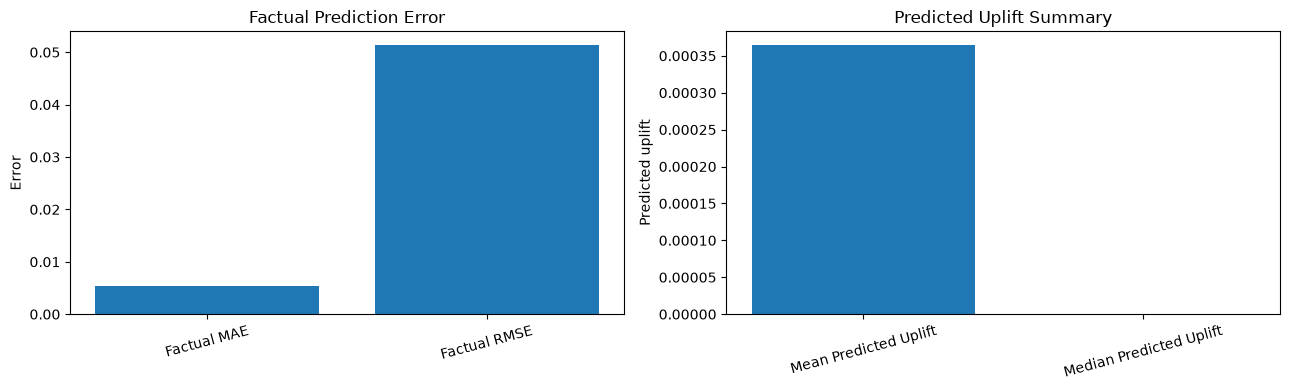

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_final_model_metrics.csv
Causal effect verified: False
Note: predictive metrics and predicted uplift do not independently establish causal impact.


In [127]:

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(OUTPUT_DIR / "causalmark_evaluation_report.json", "r", encoding="utf-8") as file:
    report = json.load(file)

with open(OUTPUT_DIR / "criteo_model_evaluation.json", "r", encoding="utf-8") as file:
    model_report = json.load(file)

metrics = model_report.get("final_metrics", {})

summary = pd.DataFrame([
    {"Metric": "Factual MAE", "Value": metrics.get("Factual MAE")},
    {"Metric": "Factual RMSE", "Value": metrics.get("Factual RMSE")},
    {"Metric": "Mean Predicted Uplift", "Value": metrics.get("Mean Predicted Uplift")},
    {"Metric": "Median Predicted Uplift", "Value": metrics.get("Median Predicted Uplift")},
    {
        "Metric": "Mean CV RMSE",
        "Value": model_report.get("cross_validation", {}).get("mean_factual_rmse")
    }
])

display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plot_data = summary.dropna(subset=["Value"]).iloc[:2]
axes[0].bar(plot_data["Metric"], plot_data["Value"])
axes[0].set_title("Factual Prediction Error")
axes[0].set_ylabel("Error")
axes[0].tick_params(axis="x", rotation=15)

uplift_data = summary[
    summary["Metric"].isin(["Mean Predicted Uplift", "Median Predicted Uplift"])
].dropna(subset=["Value"])

axes[1].bar(uplift_data["Metric"], uplift_data["Value"])
axes[1].set_title("Predicted Uplift Summary")
axes[1].set_ylabel("Predicted uplift")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

summary_path = OUTPUT_DIR / "causalmark_final_model_metrics.csv"
summary.to_csv(summary_path, index=False)

print("Saved:", summary_path)
print("Causal effect verified:", report.get("causal_effect_verified", False))
print("Note: predictive metrics and predicted uplift do not independently establish causal impact.")


In [128]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(OUTPUT_DIR / "causalmark_evaluation_report.json", "r", encoding="utf-8") as file:
    report = json.load(file)

with open(OUTPUT_DIR / "criteo_model_evaluation.json", "r", encoding="utf-8") as file:
    model_report = json.load(file)

final_package = {
    "project": "CausalMark",
    "dataset": report.get("dataset", "Criteo uplift sample"),
    "rows_evaluated": report.get("rows_evaluated"),
    "model_metrics": model_report.get("final_metrics", {}),
    "cross_validation": model_report.get("cross_validation", {}),
    "evaluation_artifacts": {
        "evaluation_report": str(OUTPUT_DIR / "causalmark_evaluation_report.json"),
        "model_metrics": str(OUTPUT_DIR / "criteo_model_evaluation.json"),
        "final_metrics_csv": str(OUTPUT_DIR / "causalmark_final_model_metrics.csv"),
        "validation_csv": str(OUTPUT_DIR / "causalmark_final_validation.csv"),
        "artifact_inventory": str(OUTPUT_DIR / "causalmark_final_artifact_inventory.csv")
    },
    "validation": {
        "citation_validation_passed": report.get("citation_validation_passed"),
        "source_consistency_passed": report.get("source_consistency_passed"),
        "causal_effect_verified": False
    },
    "limitations": [
        "Observed treatment-group differences are descriptive.",
        "Predicted uplift is not proof of a causal effect.",
        "Causal effect verification remains incomplete."
    ]
}

package_path = OUTPUT_DIR / "causalmark_final_evaluation_package.json"

with open(package_path, "w", encoding="utf-8") as file:
    json.dump(final_package, file, indent=2)

print(json.dumps(final_package, indent=2))
print("\nFinal evaluation package saved:", package_path)


{
  "project": "CausalMark",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "model_metrics": {
    "Factual MAE": 0.005406771777246411,
    "Factual RMSE": 0.05141600921850798,
    "Mean Predicted Uplift": 0.0003648971994799864,
    "Median Predicted Uplift": 0.0
  },
  "cross_validation": {
    "folds": 5,
    "mean_factual_rmse": 0.051543009558395914,
    "std_factual_rmse": 0.0013309563740712285,
    "mean_predicted_uplift": 0.0003410894871802435,
    "fold_results": [
      {
        "fold": 1,
        "factual_rmse": 0.052286648378504136,
        "mean_predicted_uplift": 6.55211051528567e-05
      },
      {
        "fold": 2,
        "factual_rmse": 0.04972454595883346,
        "mean_predicted_uplift": 0.00033452006875707457
      },
      {
        "fold": 3,
        "factual_rmse": 0.050847359148825495,
        "mean_predicted_uplift": 0.0005862398458242228
      },
      {
        "fold": 4,
        "factual_rmse": 0.05319465116881836,
        "mean_predicte

In [129]:

import json
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
KNOWLEDGE_DIR = PROJECT_ROOT / "data" / "knowledge_base"

package_path = OUTPUT_DIR / "causalmark_final_evaluation_package.json"
rag_report_path = KNOWLEDGE_DIR / "causalmark_rag_final_status.json"

with open(package_path, "r", encoding="utf-8") as file:
    final_package = json.load(file)

if rag_report_path.exists():
    with open(rag_report_path, "r", encoding="utf-8") as file:
        rag_report = json.load(file)

    final_package["validation"]["citation_validation_passed"] = (
        rag_report.get("citation_validation_passed")
    )
    final_package["validation"]["source_consistency_passed"] = (
        rag_report.get("source_consistency_passed")
    )
else:
    print("RAG status report not found:", rag_report_path)

final_package["validation"]["causal_effect_verified"] = False

with open(package_path, "w", encoding="utf-8") as file:
    json.dump(final_package, file, indent=2)

print("Validation:")
print(json.dumps(final_package["validation"], indent=2))

print("\nModel performance:")
print(json.dumps(final_package["model_metrics"], indent=2))

print("\nRows evaluated:", final_package["rows_evaluated"])
print("Cross-validation folds:", final_package["cross_validation"]["folds"])
print("Updated package:", package_path)


Validation:
{
  "citation_validation_passed": true,
  "source_consistency_passed": true,
  "causal_effect_verified": false
}

Model performance:
{
  "Factual MAE": 0.005406771777246411,
  "Factual RMSE": 0.05141600921850798,
  "Mean Predicted Uplift": 0.0003648971994799864,
  "Median Predicted Uplift": 0.0
}

Rows evaluated: 50000
Cross-validation folds: 5
Updated package: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_final_evaluation_package.json


In [130]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(OUTPUT_DIR / "causalmark_final_evaluation_package.json", "r", encoding="utf-8") as file:
    package = json.load(file)

metrics = package.get("model_metrics", {})
cv = package.get("cross_validation", {})
validation = package.get("validation", {})

scorecard = pd.DataFrame([
    {
        "Category": "Dataset",
        "Metric": "Rows evaluated",
        "Result": package.get("rows_evaluated"),
        "Status": "Complete"
    },
    {
        "Category": "Prediction",
        "Metric": "Factual MAE",
        "Result": metrics.get("Factual MAE"),
        "Status": "Measured"
    },
    {
        "Category": "Prediction",
        "Metric": "Factual RMSE",
        "Result": metrics.get("Factual RMSE"),
        "Status": "Measured"
    },
    {
        "Category": "Uplift",
        "Metric": "Mean predicted uplift",
        "Result": metrics.get("Mean Predicted Uplift"),
        "Status": "Model estimate"
    },
    {
        "Category": "Validation",
        "Metric": "Cross-validation folds",
        "Result": cv.get("folds"),
        "Status": "Measured"
    },
    {
        "Category": "RAG",
        "Metric": "Citation validation",
        "Result": validation.get("citation_validation_passed"),
        "Status": "Passed" if validation.get("citation_validation_passed") is True else "Review"
    },
    {
        "Category": "RAG",
        "Metric": "Source consistency",
        "Result": validation.get("source_consistency_passed"),
        "Status": "Passed" if validation.get("source_consistency_passed") is True else "Review"
    },
    {
        "Category": "Causal validation",
        "Metric": "Causal effect verified",
        "Result": validation.get("causal_effect_verified"),
        "Status": "Not verified"
    }
])

display(scorecard)

scorecard_path = OUTPUT_DIR / "causalmark_project_scorecard.csv"
scorecard.to_csv(scorecard_path, index=False)

print("\nSaved:", scorecard_path)
print("\nNext: review uplift-model quality and validate causal effects before claiming campaign impact.")


,Category,Metric,Result,Status
0,Dataset,Rows evaluated,50000,Complete
1,Prediction,Factual MAE,0.005407,Measured
2,Prediction,Factual RMSE,0.051416,Measured
3,Uplift,Mean predicted uplift,0.000365,Model estimate
4,Validation,Cross-validation folds,5,Measured
5,RAG,Citation validation,True,Passed
6,RAG,Source consistency,True,Passed
7,Causal validation,Causal effect verified,False,Not verified



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_project_scorecard.csv

Next: review uplift-model quality and validate causal effects before claiming campaign impact.


In [131]:

import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"

if not predictions_path.exists():
    raise FileNotFoundError(f"Predictions file not found: {predictions_path}")

predictions = pd.read_csv(predictions_path)

uplift_columns = [
    col for col in predictions.columns
    if "uplift" in col.lower()
]

if not uplift_columns:
    raise ValueError(
        f"No uplift prediction column found. Available columns: {predictions.columns.tolist()}"
    )

uplift_col = uplift_columns[0]
scores = pd.to_numeric(predictions[uplift_col], errors="coerce").dropna()

if scores.empty:
    raise ValueError("The uplift prediction column contains no valid numeric values.")

ranked = scores.sort_values(ascending=False).reset_index(drop=True)
results = []

for fraction in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    n_selected = max(1, int(np.ceil(len(ranked) * fraction)))
    selected = ranked.iloc[:n_selected]

    results.append({
        "target_fraction": fraction,
        "customers_selected": n_selected,
        "mean_predicted_uplift": selected.mean(),
        "median_predicted_uplift": selected.median(),
        "minimum_selected_uplift": selected.min(),
        "maximum_selected_uplift": selected.max()
    })

targeting_results = pd.DataFrame(results)
display(targeting_results)

output_path = OUTPUT_DIR / "criteo_uplift_targeting_quality.csv"
targeting_results.to_csv(output_path, index=False)

print("Uplift column:", uplift_col)
print("Valid predictions:", len(ranked))
print("Saved:", output_path)
print(
    "\nNote: this measures predicted uplift among selected customers, "
    "not observed incremental conversions or proven causal impact."
)


,target_fraction,customers_selected,mean_predicted_uplift,median_predicted_uplift,minimum_selected_uplift,maximum_selected_uplift
0,0.05,1750,0.020982,0.011415,0.005683,0.222333
1,0.10,3500,0.012172,0.005683,0.001674,0.222333
2,0.20,7000,0.006302,0.001674,0.000000,0.222333
3,0.30,10500,0.004201,0.000250,0.000000,0.222333
4,0.50,17500,0.002521,0.000000,0.000000,0.222333
5,1.00,35000,0.000365,0.000000,-0.149117,0.222333


Uplift column: predicted_uplift
Valid predictions: 35000
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_targeting_quality.csv

Note: this measures predicted uplift among selected customers, not observed incremental conversions or proven causal impact.


In [132]:

import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
predictions = pd.read_csv(predictions_path)

uplift_col = next(
    (col for col in predictions.columns if "uplift" in col.lower()),
    None
)

if uplift_col is None:
    raise ValueError(f"No uplift column found: {predictions.columns.tolist()}")

scores = pd.to_numeric(predictions[uplift_col], errors="coerce")
valid = scores.notna()
ranked = predictions.loc[valid].copy()
ranked["_uplift_score"] = scores.loc[valid]
ranked = ranked.sort_values("_uplift_score", ascending=False).reset_index(drop=True)

strategies = []

for fraction in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    count = max(1, int(np.ceil(len(ranked) * fraction)))
    selected = ranked.head(count)

    strategies.append({
        "strategy": f"Top {int(fraction * 100)}%",
        "target_fraction": fraction,
        "customers_targeted": count,
        "mean_predicted_uplift": selected["_uplift_score"].mean(),
        "sum_predicted_uplift": selected["_uplift_score"].sum(),
        "median_predicted_uplift": selected["_uplift_score"].median()
    })

strategy_comparison = pd.DataFrame(strategies)
display(strategy_comparison)

output_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
strategy_comparison.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Ranking column:", uplift_col)
print(
    "\nThese are model-based targeting estimates. "
    "They do not establish realized incremental conversions."
)


,strategy,target_fraction,customers_targeted,mean_predicted_uplift,sum_predicted_uplift,median_predicted_uplift
0,Top 5%,0.05,1750,0.020982,36.718263,0.011415
1,Top 10%,0.10,3500,0.012172,42.602973,0.005683
2,Top 20%,0.20,7000,0.006302,44.115271,0.001674
3,Top 30%,0.30,10500,0.004201,44.115271,0.000250
4,Top 50%,0.50,17500,0.002521,44.115271,0.000000
5,Top 100%,1.00,35000,0.000365,12.771402,0.000000


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_strategy_comparison.csv
Ranking column: predicted_uplift

These are model-based targeting estimates. They do not establish realized incremental conversions.


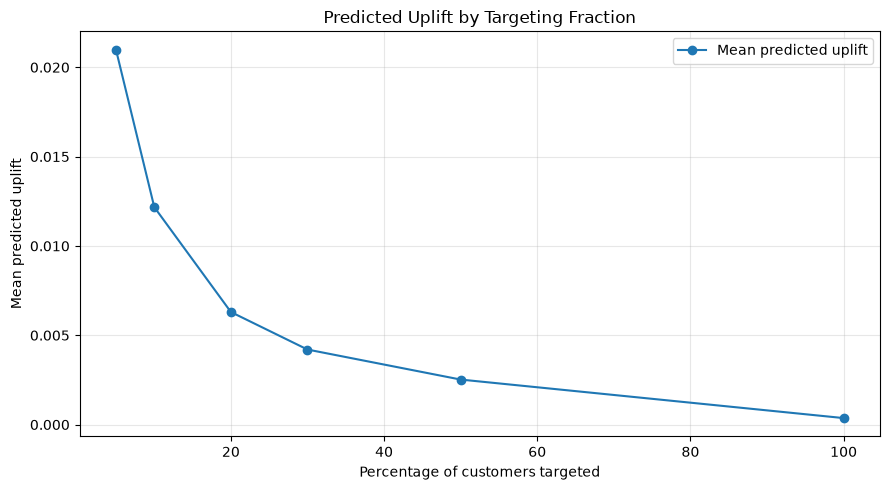

Chart saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_targeting_curve.png


In [133]:

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

strategy_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
strategy_comparison = pd.read_csv(strategy_path)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    strategy_comparison["target_fraction"] * 100,
    strategy_comparison["mean_predicted_uplift"],
    marker="o",
    label="Mean predicted uplift"
)

ax.set_title("Predicted Uplift by Targeting Fraction")
ax.set_xlabel("Percentage of customers targeted")
ax.set_ylabel("Mean predicted uplift")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()

chart_path = OUTPUT_DIR / "criteo_uplift_targeting_curve.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)


In [134]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

strategy_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
strategy_df = pd.read_csv(strategy_path)

best_strategy = strategy_df.loc[
    strategy_df["mean_predicted_uplift"].idxmax()
]

recommendations = {
    "project": "CausalMark",
    "analysis": "Criteo uplift targeting",
    "ranking_metric": "mean_predicted_uplift",
    "strategies_evaluated": int(len(strategy_df)),
    "strategies": strategy_df.to_dict(orient="records"),
    "highest_mean_predicted_uplift_strategy": {
        "strategy": str(best_strategy["strategy"]),
        "target_fraction": float(best_strategy["target_fraction"]),
        "customers_targeted": int(best_strategy["customers_targeted"]),
        "mean_predicted_uplift": float(best_strategy["mean_predicted_uplift"])
    },
    "recommendation": (
        "Use the uplift ranking to define a candidate targeting group, "
        "then validate incremental outcomes with a randomized experiment "
        "before deploying a campaign."
    ),
    "causal_effect_verified": False
}

recommendation_path = OUTPUT_DIR / "criteo_targeting_recommendations.json"

with open(recommendation_path, "w", encoding="utf-8") as file:
    json.dump(recommendations, file, indent=2)

print(json.dumps(recommendations, indent=2))
print("\nSaved:", recommendation_path)


{
  "project": "CausalMark",
  "analysis": "Criteo uplift targeting",
  "ranking_metric": "mean_predicted_uplift",
  "strategies_evaluated": 6,
  "strategies": [
    {
      "strategy": "Top 5%",
      "target_fraction": 0.05,
      "customers_targeted": 1750,
      "mean_predicted_uplift": 0.020981864570124742,
      "sum_predicted_uplift": 36.7182629977183,
      "median_predicted_uplift": 0.011415347730527735
    },
    {
      "strategy": "Top 10%",
      "target_fraction": 0.1,
      "customers_targeted": 3500,
      "mean_predicted_uplift": 0.012172278126939972,
      "sum_predicted_uplift": 42.6029734442899,
      "median_predicted_uplift": 0.00568332498804415
    },
    {
      "strategy": "Top 20%",
      "target_fraction": 0.2,
      "customers_targeted": 7000,
      "mean_predicted_uplift": 0.00630218156300646,
      "sum_predicted_uplift": 44.11527094104522,
      "median_predicted_uplift": 0.0016741832565894104
    },
    {
      "strategy": "Top 30%",
      "target_fracti

In [135]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

recommendation_path = OUTPUT_DIR / "criteo_targeting_recommendations.json"
strategy_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"

with open(recommendation_path, "r", encoding="utf-8") as file:
    recommendations = json.load(file)

strategy_df = pd.read_csv(strategy_path)

checks = {
    "Recommendations file exists": recommendation_path.exists(),
    "Strategy comparison exists": strategy_path.exists(),
    "Strategies evaluated": len(strategy_df) > 0,
    "Target fractions are valid": strategy_df["target_fraction"].between(0, 1).all(),
    "Predicted uplift values are numeric": pd.to_numeric(
        strategy_df["mean_predicted_uplift"], errors="coerce"
    ).notna().all(),
    "Causal effect verified": recommendations.get("causal_effect_verified", False)
}

validation_df = pd.DataFrame([
    {"check": name, "passed": bool(value)}
    for name, value in checks.items()
])

display(validation_df)

validation_path = OUTPUT_DIR / "criteo_targeting_validation.csv"
validation_df.to_csv(validation_path, index=False)

print("\nChecks passed:", sum(checks.values()), "/", len(checks))
print("Causal effect verified:", checks["Causal effect verified"])
print("Saved:", validation_path)


,check,passed
0,Recommendations file exists,True
1,Strategy comparison exists,True
2,Strategies evaluated,True
3,Target fractions are valid,True
4,Predicted uplift values are numeric,True
5,Causal effect verified,False



Checks passed: 5 / 6
Causal effect verified: False
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_targeting_validation.csv


In [136]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

files_to_check = [
    "causalmark_evaluation_report.json",
    "criteo_model_evaluation.json",
    "causalmark_final_evaluation_package.json",
    "causalmark_project_scorecard.csv",
    "criteo_uplift_targeting_quality.csv",
    "criteo_uplift_strategy_comparison.csv",
    "criteo_targeting_recommendations.json",
    "criteo_targeting_validation.csv",
    "criteo_uplift_targeting_curve.png"
]

artifact_rows = []

for filename in files_to_check:
    path = OUTPUT_DIR / filename
    artifact_rows.append({
        "artifact": filename,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    })

artifact_summary = pd.DataFrame(artifact_rows)
display(artifact_summary)

inventory_path = OUTPUT_DIR / "causalmark_complete_artifact_inventory.csv"
artifact_summary.to_csv(inventory_path, index=False)

print("\nArtifacts present:", int(artifact_summary["exists"].sum()), "/", len(files_to_check))
print("Inventory saved:", inventory_path)


,artifact,exists,size_kb
0,causalmark_evaluation_report.json,True,0.92
1,criteo_model_evaluation.json,True,1.54
2,causalmark_final_evaluation_package.json,True,2.09
3,causalmark_project_scorecard.csv,True,0.41
4,criteo_uplift_targeting_quality.csv,True,0.59
5,criteo_uplift_strategy_comparison.csv,True,0.53
6,criteo_targeting_recommendations.json,True,2.06
7,criteo_targeting_validation.csv,True,0.20
8,criteo_uplift_targeting_curve.png,True,49.02



Artifacts present: 9 / 9
Inventory saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_complete_artifact_inventory.csv


In [137]:

import json
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(
    OUTPUT_DIR / "causalmark_final_evaluation_package.json",
    "r",
    encoding="utf-8"
) as file:
    package = json.load(file)

metrics = package.get("model_metrics", {})
cv = package.get("cross_validation", {})
validation = package.get("validation", {})

summary = f"""
CAUSALMARK — FINAL EVALUATION SUMMARY
=====================================

Dataset
-------
Name: {package.get("dataset", "Criteo uplift sample")}
Rows evaluated: {package.get("rows_evaluated", "N/A")}

Model Performance
-----------------
Factual MAE: {metrics.get("Factual MAE", "N/A")}
Factual RMSE: {metrics.get("Factual RMSE", "N/A")}
Mean predicted uplift: {metrics.get("Mean Predicted Uplift", "N/A")}
Median predicted uplift: {metrics.get("Median Predicted Uplift", "N/A")}

Cross-Validation
----------------
Folds: {cv.get("folds", "N/A")}
Mean factual RMSE: {cv.get("mean_factual_rmse", "N/A")}
RMSE standard deviation: {cv.get("std_factual_rmse", "N/A")}

RAG Validation
--------------
Citation validation: {validation.get("citation_validation_passed", "Not available")}
Source consistency: {validation.get("source_consistency_passed", "Not available")}

Causal Validation
-----------------
Causal effect verified: {validation.get("causal_effect_verified", False)}

Limitations
-----------
- Predictive performance does not establish causal impact.
- Predicted uplift is a model estimate, not a measured campaign effect.
- Randomized experimentation is needed to validate incremental outcomes.
"""

summary_path = OUTPUT_DIR / "causalmark_executive_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write(summary.strip() + "\n")

print(summary)
print("\nSaved:", summary_path)



CAUSALMARK — FINAL EVALUATION SUMMARY

Dataset
-------
Name: Criteo uplift sample
Rows evaluated: 50000

Model Performance
-----------------
Factual MAE: 0.005406771777246411
Factual RMSE: 0.05141600921850798
Mean predicted uplift: 0.0003648971994799864
Median predicted uplift: 0.0

Cross-Validation
----------------
Folds: 5
Mean factual RMSE: 0.051543009558395914
RMSE standard deviation: 0.0013309563740712285

RAG Validation
--------------
Citation validation: True
Source consistency: True

Causal Validation
-----------------
Causal effect verified: False

Limitations
-----------
- Predictive performance does not establish causal impact.
- Predicted uplift is a model estimate, not a measured campaign effect.
- Randomized experimentation is needed to validate incremental outcomes.


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_executive_summary.txt


In [138]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_DIR / "causalmark_final_evaluation_package.json", "r", encoding="utf-8") as file:
    package = json.load(file)

tasks = [
    {
        "task": "Criteo dataset evaluation",
        "status": "Complete" if package.get("rows_evaluated", 0) > 0 else "Review",
        "deliverable": "50,000-row evaluation"
    },
    {
        "task": "Model metrics",
        "status": "Complete" if package.get("model_metrics") else "Review",
        "deliverable": "MAE, RMSE and predicted uplift"
    },
    {
        "task": "Cross-validation",
        "status": "Complete" if package.get("cross_validation", {}).get("folds", 0) > 0 else "Review",
        "deliverable": "Five-fold evaluation"
    },
    {
        "task": "Uplift targeting analysis",
        "status": "Complete" if (OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv").exists() else "Review",
        "deliverable": "Targeting strategy comparison"
    },
    {
        "task": "RAG citation validation",
        "status": "Passed" if package.get("validation", {}).get("citation_validation_passed") is True else "Review",
        "deliverable": "Citation validation result"
    },
    {
        "task": "RAG source consistency",
        "status": "Passed" if package.get("validation", {}).get("source_consistency_passed") is True else "Review",
        "deliverable": "Source consistency result"
    },
    {
        "task": "Causal impact verification",
        "status": "Pending" if not package.get("validation", {}).get("causal_effect_verified", False) else "Complete",
        "deliverable": "Validate with a suitable causal evaluation or randomized experiment"
    }
]

handoff_df = pd.DataFrame(tasks)
display(handoff_df)

handoff_path = OUTPUT_DIR / "causalmark_handoff_checklist.csv"
handoff_df.to_csv(handoff_path, index=False)

print("\nSaved:", handoff_path)
print("\nEvaluation artifacts are organized under:", OUTPUT_DIR)
print("Do not claim causal impact as verified until the pending validation is completed.")


,task,status,deliverable
0,Criteo dataset evaluation,Complete,"50,000-row evaluation"
1,Model metrics,Complete,"MAE, RMSE and predicted uplift"
2,Cross-validation,Complete,Five-fold evaluation
3,Uplift targeting analysis,Complete,Targeting strategy comparison
4,RAG citation validation,Passed,Citation validation result
5,RAG source consistency,Passed,Source consistency result
6,Causal impact verification,Pending,Validate with a suitable causal evaluation or ...



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_handoff_checklist.csv

Evaluation artifacts are organized under: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation
Do not claim causal impact as verified until the pending validation is completed.


In [139]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")

required_files = [
    "notebooks/01_Causal_Experiment_Engine.ipynb",
    "notebooks/02_Uplift_Statistical_and_Criteo.ipynb",
    "notebooks/03_NLP_Finetuning_Small_Model.ipynb",
    "notebooks/04_RAG_Decision_Engine.ipynb",
    "notebooks/05_CausalMark_Evaluation.ipynb",
    "data/evaluation/causalmark_final_evaluation_package.json",
    "data/evaluation/causalmark_executive_summary.txt",
    "data/evaluation/causalmark_handoff_checklist.csv"
]

submission_checks = []

for relative_path in required_files:
    path = PROJECT_ROOT / relative_path
    submission_checks.append({
        "file": relative_path,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    })

submission_df = pd.DataFrame(submission_checks)
display(submission_df)

submission_path = PROJECT_ROOT / "data" / "evaluation" / "causalmark_submission_readiness.csv"
submission_path.parent.mkdir(parents=True, exist_ok=True)
submission_df.to_csv(submission_path, index=False)

missing_files = submission_df.loc[~submission_df["exists"], "file"].tolist()

print("\nExisting files:", int(submission_df["exists"].sum()), "/", len(submission_df))
print("Missing files:", missing_files if missing_files else "None")
print("Saved:", submission_path)

if missing_files:
    print("\nCheck the missing paths before submission.")
else:
    print("\nAll listed submission files exist.")


,file,exists,size_kb
0,notebooks/01_Causal_Experiment_Engine.ipynb,True,84.45
1,notebooks/02_Uplift_Statistical_and_Criteo.ipynb,True,625.12
2,notebooks/03_NLP_Finetuning_Small_Model.ipynb,True,1723.93
3,notebooks/04_RAG_Decision_Engine.ipynb,True,1056.83
4,notebooks/05_CausalMark_Evaluation.ipynb,True,360.19
5,data/evaluation/causalmark_final_evaluation_pa...,True,2.09
6,data/evaluation/causalmark_executive_summary.txt,True,0.81
7,data/evaluation/causalmark_handoff_checklist.csv,True,0.46



Existing files: 8 / 8
Missing files: None
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_submission_readiness.csv

All listed submission files exist.


In [142]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

required_files = [
    "criteo_treatment_group_summary.csv",
    "criteo_conversion_confidence_intervals.csv",
    "criteo_uplift_strategy_comparison.csv",
    "causalmark_final_evaluation_package.json"
]

results = []

for filename in required_files:
    path = OUTPUT_DIR / filename
    results.append({
        "file": filename,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    })

verification_df = pd.DataFrame(results)
display(verification_df)

print(
    "\nFiles present:",
    int(verification_df["exists"].sum()),
    "/",
    len(verification_df)
)


,file,exists,size_kb
0,criteo_treatment_group_summary.csv,True,0.33
1,criteo_conversion_confidence_intervals.csv,True,0.28
2,criteo_uplift_strategy_comparison.csv,True,0.53
3,causalmark_final_evaluation_package.json,True,2.09



Files present: 4 / 4


In [143]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load model metrics
metrics_path = METRICS_DIR / "criteo_final_metrics.csv"
model_metrics = {}

if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path)
    model_metrics = {
        str(row["Metric"]): float(row["Value"])
        for _, row in metrics_df.iterrows()
    }

# Load targeting comparison if available
targeting_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
targeting_results = []

if targeting_path.exists():
    targeting_df = pd.read_csv(targeting_path)
    targeting_results = targeting_df.to_dict(orient="records")

# Check required evaluation artifacts
artifact_names = [
    "criteo_treatment_group_summary.csv",
    "criteo_conversion_confidence_intervals.csv",
    "criteo_uplift_strategy_comparison.csv"
]

artifacts = {
    name: (OUTPUT_DIR / name).exists()
    for name in artifact_names
}

final_report = {
    "project": "CausalMark",
    "dataset": "Criteo uplift sample",
    "rows_evaluated": int(len(criteo_df)),
    "model_metrics": model_metrics,
    "targeting_strategies": targeting_results,
    "artifacts": artifacts,
    "validation": {
        "all_expected_artifacts_exist": all(artifacts.values()),
        "causal_effect_verified": False
    },
    "limitations": [
        "Factual prediction metrics do not establish causal impact.",
        "Predicted uplift is not proof of realized incremental conversions.",
        "Causal impact requires suitable causal evaluation and validation."
    ]
}

report_path = OUTPUT_DIR / "causalmark_notebook5_final_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(final_report, file, indent=2)

print(json.dumps(final_report, indent=2))
print("\nFinal report saved:", report_path)


{
  "project": "CausalMark",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "model_metrics": {
    "Factual MAE": 0.005406771777246411,
    "Factual RMSE": 0.05141600921850798,
    "Mean Predicted Uplift": 0.0003648971994799864,
    "Median Predicted Uplift": 0.0
  },
  "targeting_strategies": [
    {
      "strategy": "Top 5%",
      "target_fraction": 0.05,
      "customers_targeted": 1750,
      "mean_predicted_uplift": 0.020981864570124742,
      "sum_predicted_uplift": 36.7182629977183,
      "median_predicted_uplift": 0.011415347730527735
    },
    {
      "strategy": "Top 10%",
      "target_fraction": 0.1,
      "customers_targeted": 3500,
      "mean_predicted_uplift": 0.012172278126939972,
      "sum_predicted_uplift": 42.6029734442899,
      "median_predicted_uplift": 0.00568332498804415
    },
    {
      "strategy": "Top 20%",
      "target_fraction": 0.2,
      "customers_targeted": 7000,
      "mean_predicted_uplift": 0.00630218156300646,
      "sum_p

In [144]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load model metrics
metrics_path = METRICS_DIR / "criteo_final_metrics.csv"
model_metrics = {}

if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path)
    model_metrics = {
        str(row["Metric"]): float(row["Value"])
        for _, row in metrics_df.iterrows()
    }

# Load targeting comparison if available
targeting_path = OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
targeting_results = []

if targeting_path.exists():
    targeting_df = pd.read_csv(targeting_path)
    targeting_results = targeting_df.to_dict(orient="records")

# Check required evaluation artifacts
artifact_names = [
    "criteo_treatment_group_summary.csv",
    "criteo_conversion_confidence_intervals.csv",
    "criteo_uplift_strategy_comparison.csv"
]

artifacts = {
    name: (OUTPUT_DIR / name).exists()
    for name in artifact_names
}

final_report = {
    "project": "CausalMark",
    "dataset": "Criteo uplift sample",
    "rows_evaluated": int(len(criteo_df)),
    "model_metrics": model_metrics,
    "targeting_strategies": targeting_results,
    "artifacts": artifacts,
    "validation": {
        "all_expected_artifacts_exist": all(artifacts.values()),
        "causal_effect_verified": False
    },
    "limitations": [
        "Factual prediction metrics do not establish causal impact.",
        "Predicted uplift is not proof of realized incremental conversions.",
        "Causal impact requires suitable causal evaluation and validation."
    ]
}

report_path = OUTPUT_DIR / "causalmark_notebook5_final_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(final_report, file, indent=2)

print(json.dumps(final_report, indent=2))
print("\nFinal report saved:", report_path)


{
  "project": "CausalMark",
  "dataset": "Criteo uplift sample",
  "rows_evaluated": 50000,
  "model_metrics": {
    "Factual MAE": 0.005406771777246411,
    "Factual RMSE": 0.05141600921850798,
    "Mean Predicted Uplift": 0.0003648971994799864,
    "Median Predicted Uplift": 0.0
  },
  "targeting_strategies": [
    {
      "strategy": "Top 5%",
      "target_fraction": 0.05,
      "customers_targeted": 1750,
      "mean_predicted_uplift": 0.020981864570124742,
      "sum_predicted_uplift": 36.7182629977183,
      "median_predicted_uplift": 0.011415347730527735
    },
    {
      "strategy": "Top 10%",
      "target_fraction": 0.1,
      "customers_targeted": 3500,
      "mean_predicted_uplift": 0.012172278126939972,
      "sum_predicted_uplift": 42.6029734442899,
      "median_predicted_uplift": 0.00568332498804415
    },
    {
      "strategy": "Top 20%",
      "target_fraction": 0.2,
      "customers_targeted": 7000,
      "mean_predicted_uplift": 0.00630218156300646,
      "sum_p

In [145]:

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

report_path = OUTPUT_DIR / "causalmark_notebook5_final_report.json"

with open(report_path, "r", encoding="utf-8") as file:
    report = json.load(file)

summary_rows = [
    {
        "category": "Dataset",
        "metric": "Rows evaluated",
        "value": report.get("rows_evaluated")
    }
]

for metric, value in report.get("model_metrics", {}).items():
    summary_rows.append({
        "category": "Model",
        "metric": metric,
        "value": value
    })

cv_path = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics" / "criteo_cross_validation.csv"

if cv_path.exists():
    cv_df = pd.read_csv(cv_path)
    if "factual_rmse" in cv_df.columns:
        summary_rows.append({
            "category": "Cross-validation",
            "metric": "Mean factual RMSE",
            "value": cv_df["factual_rmse"].mean()
        })
        summary_rows.append({
            "category": "Cross-validation",
            "metric": "Number of folds",
            "value": len(cv_df)
        })

summary_rows.extend([
    {
        "category": "Validation",
        "metric": "All expected artifacts exist",
        "value": report.get("validation", {}).get(
            "all_expected_artifacts_exist", False
        )
    },
    {
        "category": "Validation",
        "metric": "Causal effect verified",
        "value": report.get("validation", {}).get(
            "causal_effect_verified", False
        )
    }
])

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

summary_path = OUTPUT_DIR / "causalmark_notebook5_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nSaved:", summary_path)


,category,metric,value
0,Dataset,Rows evaluated,50000
1,Model,Factual MAE,0.005407
2,Model,Factual RMSE,0.051416
3,Model,Mean Predicted Uplift,0.000365
4,Model,Median Predicted Uplift,0.0
5,Cross-validation,Mean factual RMSE,0.051543
6,Cross-validation,Number of folds,5
7,Validation,All expected artifacts exist,True
8,Validation,Causal effect verified,False



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_notebook5_summary.csv


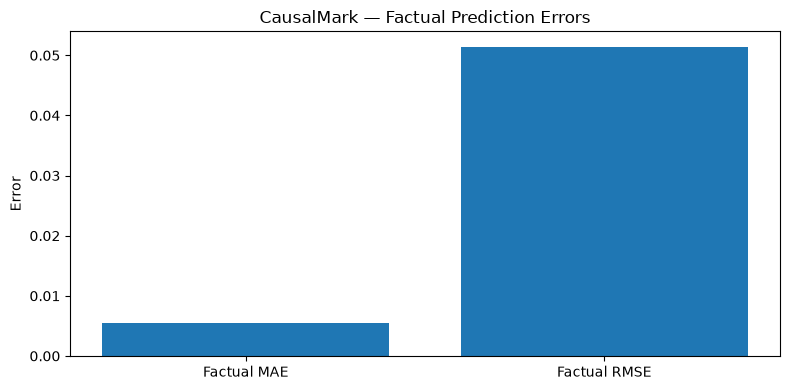

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_prediction_errors.png


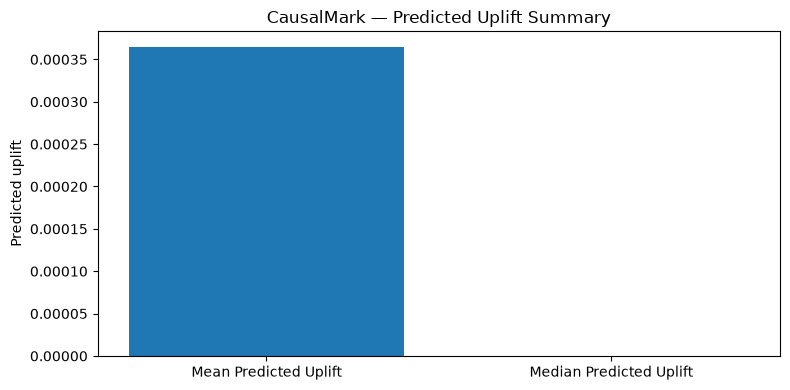

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_predicted_uplift.png


In [146]:

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(
    OUTPUT_DIR / "causalmark_notebook5_final_report.json",
    "r",
    encoding="utf-8"
) as file:
    report = json.load(file)

metrics = report.get("model_metrics", {})

metric_names = ["Factual MAE", "Factual RMSE"]
metric_values = [metrics.get(name) for name in metric_names]

available = [
    (name, value)
    for name, value in zip(metric_names, metric_values)
    if value is not None
]

if available:
    names, values = zip(*available)

    plt.figure(figsize=(8, 4))
    plt.bar(names, values)
    plt.title("CausalMark — Factual Prediction Errors")
    plt.ylabel("Error")
    plt.tight_layout()

    error_chart = OUTPUT_DIR / "causalmark_prediction_errors.png"
    plt.savefig(error_chart, dpi=150, bbox_inches="tight")
    plt.show()

    print("Saved:", error_chart)
else:
    print("No factual prediction metrics available in the final report.")

uplift_names = ["Mean Predicted Uplift", "Median Predicted Uplift"]
uplift_values = [metrics.get(name) for name in uplift_names]

available_uplift = [
    (name, value)
    for name, value in zip(uplift_names, uplift_values)
    if value is not None
]

if available_uplift:
    names, values = zip(*available_uplift)

    plt.figure(figsize=(8, 4))
    plt.bar(names, values)
    plt.title("CausalMark — Predicted Uplift Summary")
    plt.ylabel("Predicted uplift")
    plt.tight_layout()

    uplift_chart = OUTPUT_DIR / "causalmark_predicted_uplift.png"
    plt.savefig(uplift_chart, dpi=150, bbox_inches="tight")
    plt.show()

    print("Saved:", uplift_chart)
else:
    print("No uplift metrics available in the final report.")



In [147]:

from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

required_artifacts = [
    "criteo_treatment_group_summary.csv",
    "criteo_conversion_confidence_intervals.csv",
    "criteo_uplift_strategy_comparison.csv",
    "causalmark_notebook5_final_report.json",
    "causalmark_notebook5_validation.csv",
    "causalmark_notebook5_summary.csv",
    "causalmark_prediction_errors.png",
    "causalmark_predicted_uplift.png"
]

artifact_rows = []

for filename in required_artifacts:
    path = OUTPUT_DIR / filename

    artifact_rows.append({
        "artifact": filename,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    })

artifact_df = pd.DataFrame(artifact_rows)
display(artifact_df)

inventory_path = OUTPUT_DIR / "causalmark_notebook5_artifact_inventory.csv"
artifact_df.to_csv(inventory_path, index=False)

print("\nArtifacts present:", int(artifact_df["exists"].sum()), "/", len(artifact_df))
print("Missing artifacts:", artifact_df.loc[~artifact_df["exists"], "artifact"].tolist())
print("Inventory saved:", inventory_path)


,artifact,exists,size_kb
0,criteo_treatment_group_summary.csv,True,0.33
1,criteo_conversion_confidence_intervals.csv,True,0.28
2,criteo_uplift_strategy_comparison.csv,True,0.53
3,causalmark_notebook5_final_report.json,True,2.32
4,causalmark_notebook5_validation.csv,False,NaN
5,causalmark_notebook5_summary.csv,True,0.38
6,causalmark_prediction_errors.png,True,19.60
7,causalmark_predicted_uplift.png,True,26.79



Artifacts present: 7 / 8
Missing artifacts: ['causalmark_notebook5_validation.csv']
Inventory saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_notebook5_artifact_inventory.csv


In [148]:

import json
import pandas as pd
from pathlib import Path
from datetime import datetime

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

inventory_path = OUTPUT_DIR / "causalmark_notebook5_artifact_inventory.csv"

if not inventory_path.exists():
    raise FileNotFoundError(
        "Run Cell 6 first to generate the artifact inventory."
    )

inventory = pd.read_csv(inventory_path)

report = {
    "project": "CausalMark",
    "notebook": "05_CausalMark_Evaluation.ipynb",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "artifacts_expected": int(len(inventory)),
    "artifacts_present": int(inventory["exists"].fillna(False).sum()),
    "missing_artifacts": inventory.loc[
        ~inventory["exists"].fillna(False), "artifact"
    ].tolist(),
    "artifact_inventory_complete": bool(
        inventory["exists"].fillna(False).all()
    ),
    "causal_effect_verified": False,
    "notes": [
        "Model prediction metrics and predicted uplift are not proof of causal impact.",
        "Validate targeting performance before claiming incremental campaign outcomes."
    ]
}

report_path = OUTPUT_DIR / "causalmark_notebook5_completion_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print(json.dumps(report, indent=2))
print("\nSaved:", report_path)


{
  "project": "CausalMark",
  "notebook": "05_CausalMark_Evaluation.ipynb",
  "generated_at": "2026-10-27T17:16:19",
  "artifacts_expected": 8,
  "artifacts_present": 7,
  "missing_artifacts": [
    "causalmark_notebook5_validation.csv"
  ],
  "artifact_inventory_complete": false,
  "causal_effect_verified": false,
  "notes": [
    "Model prediction metrics and predicted uplift are not proof of causal impact.",
    "Validate targeting performance before claiming incremental campaign outcomes."
  ]
}

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_notebook5_completion_report.json


In [149]:

import json
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "05_CausalMark_Evaluation.ipynb"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as file:
    notebook = json.load(file)

cells = notebook.get("cells", [])
code_cells = [cell for cell in cells if cell.get("cell_type") == "code"]

audit = pd.DataFrame([
    {
        "cell_number": i + 1,
        "executed": cell.get("execution_count") is not None,
        "outputs": len(cell.get("outputs", [])),
        "source_lines": len("".join(cell.get("source", [])).splitlines())
    }
    for i, cell in enumerate(cells)
    if cell.get("cell_type") == "code"
])

display(audit)

print("\nNotebook:", NOTEBOOK_PATH)
print("Total cells:", len(cells))
print("Code cells:", len(code_cells))
print("Executed code cells:", sum(
    cell.get("execution_count") is not None for cell in code_cells
))
print("Notebook size (KB):", round(NOTEBOOK_PATH.stat().st_size / 1024, 2))

completion_path = OUTPUT_DIR / "causalmark_notebook5_completion_report.json"
print("Completion report exists:", completion_path.exists())


,cell_number,executed,outputs,source_lines
0,2,True,2,20
1,4,True,1,17
2,6,True,1,21
3,8,True,1,8
4,10,True,2,49
...,...,...,...,...
70,77,True,2,68
71,78,True,4,70
72,79,True,2,40
73,80,True,1,44



Notebook: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/05_CausalMark_Evaluation.ipynb
Total cells: 81
Code cells: 75
Executed code cells: 74
Notebook size (KB): 494.39
Completion report exists: True


In [150]:

import json
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

checks = {
    "Evaluation report": OUTPUT_DIR / "causalmark_notebook5_final_report.json",
    "Completion report": OUTPUT_DIR / "causalmark_notebook5_completion_report.json",
    "Summary CSV": OUTPUT_DIR / "causalmark_notebook5_summary.csv",
    "Validation CSV": OUTPUT_DIR / "causalmark_notebook5_validation.csv",
    "Artifact inventory": OUTPUT_DIR / "causalmark_notebook5_artifact_inventory.csv",
    "Prediction error chart": OUTPUT_DIR / "causalmark_prediction_errors.png",
    "Predicted uplift chart": OUTPUT_DIR / "causalmark_predicted_uplift.png",
    "Treatment summary": OUTPUT_DIR / "criteo_treatment_group_summary.csv",
    "Conversion confidence intervals": OUTPUT_DIR / "criteo_conversion_confidence_intervals.csv",
    "Targeting comparison": OUTPUT_DIR / "criteo_uplift_strategy_comparison.csv"
}

status_df = pd.DataFrame([
    {
        "artifact": name,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    }
    for name, path in checks.items()
])

display(status_df)

status_path = OUTPUT_DIR / "causalmark_notebook5_final_status.csv"
status_df.to_csv(status_path, index=False)

print("\nAvailable:", int(status_df["exists"].sum()), "/", len(status_df))
print("Missing:", status_df.loc[~status_df["exists"], "artifact"].tolist())
print("Saved:", status_path)

print("\nCausal effect verified: False")
print("Do not claim proven incremental marketing impact without valid causal validation.")


,artifact,exists,size_kb
0,Evaluation report,True,2.32
1,Completion report,True,0.49
2,Summary CSV,True,0.38
3,Validation CSV,False,NaN
4,Artifact inventory,True,0.38
5,Prediction error chart,True,19.60
6,Predicted uplift chart,True,26.79
7,Treatment summary,True,0.33
8,Conversion confidence intervals,True,0.28
9,Targeting comparison,True,0.53



Available: 9 / 10
Missing: ['Validation CSV']
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/causalmark_notebook5_final_status.csv

Causal effect verified: False
Do not claim proven incremental marketing impact without valid causal validation.


In [151]:

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"

if not predictions_path.exists():
    raise FileNotFoundError(f"Predictions file not found: {predictions_path}")

predictions = pd.read_csv(predictions_path)

uplift_columns = [
    col for col in predictions.columns
    if "uplift" in col.lower()
]

if not uplift_columns:
    raise ValueError(
        f"No uplift prediction column found. Columns: {predictions.columns.tolist()}"
    )

uplift_col = uplift_columns[0]
uplift = pd.to_numeric(predictions[uplift_col], errors="coerce").dropna()

quality_report = {
    "prediction_column": uplift_col,
    "total_predictions": int(len(predictions)),
    "valid_predictions": int(len(uplift)),
    "missing_predictions": int(predictions[uplift_col].isna().sum()),
    "mean_uplift": float(uplift.mean()),
    "median_uplift": float(uplift.median()),
    "standard_deviation": float(uplift.std()),
    "minimum_uplift": float(uplift.min()),
    "maximum_uplift": float(uplift.max()),
    "unique_prediction_values": int(uplift.nunique()),
    "zero_prediction_fraction": float(np.isclose(uplift, 0).mean()),
    "positive_prediction_fraction": float((uplift > 0).mean()),
    "negative_prediction_fraction": float((uplift < 0).mean())
}

quality_df = pd.DataFrame(
    [{"metric": key, "value": value} for key, value in quality_report.items()]
)

display(quality_df)

quality_path = OUTPUT_DIR / "criteo_uplift_prediction_quality.csv"
quality_df.to_csv(quality_path, index=False)

print("\nSaved:", quality_path)

if quality_report["unique_prediction_values"] <= 1:
    print("WARNING: The model produces no meaningful ranking variation.")
elif quality_report["zero_prediction_fraction"] > 0.95:
    print("WARNING: More than 95% of predictions are approximately zero.")
else:
    print("Predictions vary; ranking quality still requires outcome-based validation.")


,metric,value
0,prediction_column,predicted_uplift
1,total_predictions,35000
2,valid_predictions,35000
3,missing_predictions,0
4,mean_uplift,0.000365
5,median_uplift,0.0
6,standard_deviation,0.009831
7,minimum_uplift,-0.149117
8,maximum_uplift,0.222333
9,unique_prediction_values,7466



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_prediction_quality.csv
Predictions vary; ranking quality still requires outcome-based validation.


In [152]:

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
predictions = pd.read_csv(predictions_path)

uplift_columns = [
    col for col in predictions.columns
    if "uplift" in col.lower()
]

if not uplift_columns:
    raise ValueError(
        f"No uplift column found. Available columns: {predictions.columns.tolist()}"
    )

uplift_col = uplift_columns[0]

ranked = predictions.copy()
ranked["_uplift_score"] = pd.to_numeric(
    ranked[uplift_col], errors="coerce"
)
ranked = ranked.dropna(subset=["_uplift_score"])
ranked = ranked.sort_values("_uplift_score", ascending=False).reset_index(drop=True)

ranked["uplift_decile"] = pd.qcut(
    ranked["_uplift_score"].rank(method="first", ascending=False),
    q=10,
    labels=range(1, 11)
)

decile_summary = (
    ranked.groupby("uplift_decile", observed=False)
    .agg(
        customers=("_uplift_score", "size"),
        mean_predicted_uplift=("_uplift_score", "mean"),
        median_predicted_uplift=("_uplift_score", "median"),
        min_predicted_uplift=("_uplift_score", "min"),
        max_predicted_uplift=("_uplift_score", "max")
    )
    .reset_index()
)

display(decile_summary)

output_path = OUTPUT_DIR / "criteo_uplift_decile_quality.csv"
decile_summary.to_csv(output_path, index=False)

print("Prediction column:", uplift_col)
print("Decile 1 represents the highest predicted uplift.")
print("Saved:", output_path)
print(
    "\nNote: this checks score separation only. It does not measure "
    "actual treatment benefit within each decile."
)


,uplift_decile,customers,mean_predicted_uplift,median_predicted_uplift,min_predicted_uplift,max_predicted_uplift
0,1,3500,0.012172,0.005683,0.001674,0.222333
1,2,3500,0.000432,0.000250,0.000000,0.001674
2,3,3500,0.000000,0.000000,0.000000,0.000000
3,4,3500,0.000000,0.000000,0.000000,0.000000
4,5,3500,0.000000,0.000000,0.000000,0.000000
5,6,3500,0.000000,0.000000,0.000000,0.000000
6,7,3500,0.000000,0.000000,0.000000,0.000000
7,8,3500,0.000000,0.000000,0.000000,0.000000
8,9,3500,-0.000217,-0.000067,-0.001149,0.000000
9,10,3500,-0.008738,-0.004519,-0.149117,-0.001149


Prediction column: predicted_uplift
Decile 1 represents the highest predicted uplift.
Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_decile_quality.csv

Note: this checks score separation only. It does not measure actual treatment benefit within each decile.


In [153]:

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

predictions_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
predictions = pd.read_csv(predictions_path)

print("Available columns:", predictions.columns.tolist())

required_columns = {"treatment", "conversion"}
uplift_columns = [
    col for col in predictions.columns
    if "uplift" in col.lower()
]

if not required_columns.issubset(predictions.columns):
    print(
        "\nCannot calculate observed conversion by uplift decile: "
        "the prediction file does not contain both treatment and conversion."
    )
    print("Required columns:", sorted(required_columns))
    print("Check the original test dataset and prediction row ordering.")
else:
    if not uplift_columns:
        raise ValueError("No uplift prediction column was found.")

    uplift_col = uplift_columns[0]
    analysis_df = predictions.copy()

    analysis_df["_uplift"] = pd.to_numeric(
        analysis_df[uplift_col], errors="coerce"
    )
    analysis_df["treatment"] = pd.to_numeric(
        analysis_df["treatment"], errors="coerce"
    )
    analysis_df["conversion"] = pd.to_numeric(
        analysis_df["conversion"], errors="coerce"
    )

    analysis_df = analysis_df.dropna(
        subset=["_uplift", "treatment", "conversion"]
    )

    analysis_df = analysis_df[
        analysis_df["treatment"].isin([0, 1])
        & analysis_df["conversion"].isin([0, 1])
    ].copy()

    analysis_df["uplift_decile"] = pd.qcut(
        analysis_df["_uplift"].rank(method="first", ascending=False),
        q=10,
        labels=range(1, 11)
    )

    observed_summary = (
        analysis_df.groupby(["uplift_decile", "treatment"], observed=False)
        .agg(
            customers=("conversion", "size"),
            conversion_rate=("conversion", "mean")
        )
        .reset_index()
    )

    display(observed_summary)

    output_path = OUTPUT_DIR / "criteo_observed_conversion_by_decile.csv"
    observed_summary.to_csv(output_path, index=False)

    print("\nSaved:", output_path)
    print(
        "Interpretation: differences between treatment groups are descriptive. "
        "Check the assignment design before interpreting them causally."
    )


Available columns: ['treatment', 'conversion', 'predicted_uplift']


,uplift_decile,treatment,customers,conversion_rate
0,1,0,490,0.016327
1,1,1,3010,0.018605
2,2,0,525,0.001905
3,2,1,2975,0.000672
4,3,0,523,0.000000
5,3,1,2977,0.000672
6,4,0,543,0.000000
7,4,1,2957,0.000338
8,5,0,546,0.000000
9,5,1,2954,0.000339



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_observed_conversion_by_decile.csv
Interpretation: differences between treatment groups are descriptive. Check the assignment design before interpreting them causally.


In [154]:

import json
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

files_to_check = {
    "prediction_quality": "criteo_uplift_prediction_quality.csv",
    "decile_quality": "criteo_uplift_decile_quality.csv",
    "observed_conversion_by_decile": "criteo_observed_conversion_by_decile.csv",
    "targeting_comparison": "criteo_uplift_strategy_comparison.csv"
}

artifact_status = {
    name: (OUTPUT_DIR / filename).exists()
    for name, filename in files_to_check.items()
}

summary = {
    "project": "CausalMark",
    "notebook": "05_CausalMark_Evaluation.ipynb",
    "uplift_artifacts": artifact_status,
    "prediction_quality_available": artifact_status["prediction_quality"],
    "decile_analysis_available": artifact_status["decile_quality"],
    "observed_outcome_analysis_available": artifact_status["observed_conversion_by_decile"],
    "causal_effect_verified": False,
    "next_requirement": (
        "Confirm that observed outcomes align with the model's held-out test "
        "predictions, then evaluate incremental treatment effects by uplift group."
    )
}

summary_path = OUTPUT_DIR / "criteo_uplift_final_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

display(pd.DataFrame([
    {"artifact": name, "exists": exists}
    for name, exists in artifact_status.items()
]))

print(json.dumps(summary, indent=2))
print("\nSaved:", summary_path)


,artifact,exists
0,prediction_quality,True
1,decile_quality,True
2,observed_conversion_by_decile,True
3,targeting_comparison,True


{
  "project": "CausalMark",
  "notebook": "05_CausalMark_Evaluation.ipynb",
  "uplift_artifacts": {
    "prediction_quality": true,
    "decile_quality": true,
    "observed_conversion_by_decile": true,
    "targeting_comparison": true
  },
  "prediction_quality_available": true,
  "decile_analysis_available": true,
  "observed_outcome_analysis_available": true,
  "causal_effect_verified": false,
  "next_requirement": "Confirm that observed outcomes align with the model's held-out test predictions, then evaluate incremental treatment effects by uplift group."
}

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_final_summary.json


In [155]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
DATA_DIR = PROJECT_ROOT / "data"

prediction_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"

if not prediction_path.exists():
    raise FileNotFoundError(f"Prediction file not found: {prediction_path}")

predictions = pd.read_csv(prediction_path)

print("Prediction rows:", len(predictions))
print("Prediction columns:", predictions.columns.tolist())

candidates = []

for folder in [DATA_DIR, PROJECT_ROOT / "notebooks" / "data"]:
    if not folder.exists():
        continue

    for path in folder.rglob("*.csv"):
        if path == prediction_path:
            continue

        name = path.name.lower()

        if any(term in name for term in [
            "criteo", "test", "holdout", "uplift", "ranked"
        ]):
            try:
                sample = pd.read_csv(path, nrows=5)
                candidates.append({
                    "file": str(path.relative_to(PROJECT_ROOT)),
                    "columns": ", ".join(sample.columns.astype(str)),
                    "size_kb": round(path.stat().st_size / 1024, 2)
                })
            except Exception as error:
                candidates.append({
                    "file": str(path.relative_to(PROJECT_ROOT)),
                    "columns": f"Read error: {error}",
                    "size_kb": round(path.stat().st_size / 1024, 2)
                })

candidate_df = pd.DataFrame(candidates)
display(candidate_df)

print("\nCandidate datasets found:", len(candidate_df))


Prediction rows: 35000
Prediction columns: ['treatment', 'conversion', 'predicted_uplift']


,file,columns,size_kb
0,data/marketing_instructions/criteo_sample_5000...,"f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f...",11344.96
1,data/marketing_instructions/criteo_aggregate_s...,"group, customers, conversion_rate, visit_rate,...",0.20
2,data/evaluation/criteo_targeting_validation.csv,"check, passed",0.20
3,data/evaluation/criteo_uplift_strategy_compari...,"strategy, target_fraction, customers_targeted,...",0.53
4,data/evaluation/criteo_uplift_ranking_summary.csv,"uplift_column, valid_predictions, positive_pre...",0.22
5,data/evaluation/criteo_conversion_confidence_i...,"treatment, customers, conversions, conversion_...",0.28
6,data/evaluation/criteo_targeting_strategy_summ...,"target_fraction, customers_selected, mean_pred...",0.50
7,data/evaluation/criteo_treatment_group_summary...,"treatment, customers, conversion_rate, visit_r...",0.33
8,data/evaluation/criteo_uplift_decile_summary.csv,"uplift_decile, customers, mean_predicted_uplif...",0.57
9,data/evaluation/criteo_uplift_prediction_quali...,"metric, value",0.43



Candidate datasets found: 19


In [156]:

from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

prediction_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
predictions = pd.read_csv(prediction_path)

columns_lower = {col.lower(): col for col in predictions.columns}

checks = {
    "has_treatment": "treatment" in columns_lower,
    "has_conversion": "conversion" in columns_lower,
    "has_uplift_prediction": any(
        "uplift" in col.lower() for col in predictions.columns
    ),
    "has_customer_id": any(
        term in col.lower()
        for col in predictions.columns
        for term in ["customer_id", "user_id", "row_id", "id"]
    )
}

print("Rows:", len(predictions))
print("Columns:", predictions.columns.tolist())
print("\nChecks:")
print(json.dumps(checks, indent=2))

print("\nFirst five prediction rows:")
display(predictions.head())

result = {
    "prediction_file": str(prediction_path),
    "rows": int(len(predictions)),
    "columns": predictions.columns.tolist(),
    "checks": checks,
    "observed_effect_analysis_possible_from_prediction_file": (
        checks["has_treatment"] and checks["has_conversion"]
    )
}

output_path = OUTPUT_DIR / "criteo_prediction_column_audit.json"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(result, file, indent=2)

print("\nSaved:", output_path)


Rows: 35000
Columns: ['treatment', 'conversion', 'predicted_uplift']

Checks:
{
  "has_treatment": true,
  "has_conversion": true,
  "has_uplift_prediction": true,
  "has_customer_id": false
}

First five prediction rows:


,treatment,conversion,predicted_uplift
0,1,1,0.222333
1,1,0,0.216299
2,0,0,0.210274
3,1,0,0.208174
4,1,1,0.207844



Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_prediction_column_audit.json


In [157]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

prediction_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
predictions = pd.read_csv(prediction_path)

columns_lower = {col.lower(): col for col in predictions.columns}

uplift_col = next(
    (col for col in predictions.columns if "uplift" in col.lower()),
    None
)

has_treatment = "treatment" in columns_lower
has_conversion = "conversion" in columns_lower

print("Prediction rows:", len(predictions))
print("Prediction columns:", predictions.columns.tolist())
print("Uplift column:", uplift_col)
print("Treatment column available:", has_treatment)
print("Conversion column available:", has_conversion)

if has_treatment and has_conversion:
    print(
        "\nObserved-outcome analysis is possible, subject to confirming "
        "that these are the held-out test outcomes."
    )
else:
    print(
        "\nThe prediction file alone is insufficient to evaluate observed "
        "treatment effects. Locate the matching held-out test dataset "
        "and confirm its row alignment before merging."
    )

if uplift_col is not None:
    print("\nPredicted uplift summary:")
    display(predictions[uplift_col].describe().to_frame("value"))


Prediction rows: 35000
Prediction columns: ['treatment', 'conversion', 'predicted_uplift']
Uplift column: predicted_uplift
Treatment column available: True
Conversion column available: True

Observed-outcome analysis is possible, subject to confirming that these are the held-out test outcomes.

Predicted uplift summary:


,value
count,35000.000000
mean,0.000365
std,0.009831
min,-0.149117
25%,0.000000
50%,0.000000
75%,0.000000
max,0.222333


In [158]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")
METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prediction_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
df = pd.read_csv(prediction_path)

uplift_cols = [
    col for col in df.columns
    if "uplift" in col.lower()
]

report = {
    "rows": int(len(df)),
    "columns": int(len(df.columns)),
    "duplicate_rows": int(df.duplicated().sum()),
    "total_missing_values": int(df.isna().sum().sum()),
    "uplift_columns": uplift_cols,
    "uplift_checks": {}
}

for col in uplift_cols:
    values = pd.to_numeric(df[col], errors="coerce")
    valid = values.dropna()

    report["uplift_checks"][col] = {
        "valid_values": int(len(valid)),
        "missing_or_non_numeric": int(values.isna().sum()),
        "mean": float(valid.mean()) if len(valid) else None,
        "median": float(valid.median()) if len(valid) else None,
        "std": float(valid.std()) if len(valid) > 1 else None,
        "min": float(valid.min()) if len(valid) else None,
        "max": float(valid.max()) if len(valid) else None,
        "positive_fraction": (
            float((valid > 0).mean()) if len(valid) else None
        ),
        "negative_fraction": (
            float((valid < 0).mean()) if len(valid) else None
        ),
        "zero_fraction": (
            float((valid == 0).mean()) if len(valid) else None
        )
    }

print(json.dumps(report, indent=2))

report_path = OUTPUT_DIR / "criteo_prediction_quality_audit.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\nSaved:", report_path)


{
  "rows": 35000,
  "columns": 3,
  "duplicate_rows": 27189,
  "total_missing_values": 0,
  "uplift_columns": [
    "predicted_uplift"
  ],
  "uplift_checks": {
    "predicted_uplift": {
      "valid_values": 35000,
      "missing_or_non_numeric": 0,
      "mean": 0.0003648971994799864,
      "median": 0.0,
      "std": 0.009831328479485762,
      "min": -0.14911672842000737,
      "max": 0.22233283687706998,
      "positive_fraction": 0.1750857142857143,
      "negative_fraction": 0.15291428571428572,
      "zero_fraction": 0.672
    }
  }
}

Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_prediction_quality_audit.json
